# Task 3: Player Monthly Spending Prediction

**โจทย์:** ทำนายยอดเงินที่ผู้เล่นแต่ละคนจะใช้จ่ายในเกมช่วง 30 วันถัดไป (`spending_30d`, หน่วยบาท) จากข้อมูลพฤติกรรมย้อนหลัง 32 features เป็นงาน **regression**

**Metric ทางการ (สไลด์หน้า 19 และ 25):**

$$\text{NMAE score} = \frac{1}{1 + \dfrac{\sum |y - \hat{y}|}{\sum y}}$$

ค่ายิ่งสูงยิ่งดี (สูงสุด 1) เมื่อวัดบนชุดข้อมูลเดียวกัน $\sum y$ คงที่ การลด MAE หน่วยบาทจึงเท่ากับการเพิ่ม NMAE โดยตรง notebook นี้จึงใช้ **MAE เป็นเกณฑ์เลือกโมเดลและ early stopping** และรายงาน NMAE คู่กันเสมอ

## ภาพรวมและวิธีอ่าน notebook

ข้อมูล Task 3 มีลักษณะสำคัญสองข้อ คือ **ผู้เล่นเกือบครึ่งใช้จ่าย 0 บาท** (zero-inflated) และ **คนจ่ายหนักกลุ่มเล็กสร้างยอดส่วนใหญ่** (หางขวาหนัก) ลำดับงานจึงเป็นดังนี้

| ขั้น | สิ่งที่ทำ |
|---|---|
| 1–2 | ตั้งค่า environment และโหลดข้อมูลพร้อมตรวจ schema |
| 3–4 | EDA: การกระจายของ target, ความสัมพันธ์กับ features และ train/test shift |
| 5 | ตรวจความเสี่ยง leakage และแบ่ง dev / locked holdout |
| 6 | Feature engineering (ratio และ interaction features) |
| 7–8 | เปรียบเทียบโมเดล 17 แบบ ตั้งแต่ baseline ถึง two-stage และวัดผลของ feature engineering |
| 9 | จูน LightGBM ด้วย Optuna |
| 10 | 3-fold cross-validation และสร้าง ensemble จาก out-of-fold predictions |
| 11 | เปิด locked holdout ครั้งเดียวเพื่อวัดผลสุดท้าย |
| 12–13 | Error analysis และ feature importance |
| 14 | ฝึกใหม่ด้วย train ทั้งหมดและสร้างไฟล์ผลทำนาย |
| 15 | สรุปผล การใช้คำใบ้อาจารย์ และข้อจำกัด |

**หลักการที่ใช้ตลอด notebook:**
- ข้อมูล test ไม่ถูกใช้เลือก model, feature หรือ hyperparameter ใด ๆ
- locked holdout (15% ของ train) ถูกกันไว้ตั้งแต่ต้น และเปิดดูเพียงครั้งเดียวหลังเลือกโมเดลเสร็จ
- ทุกคะแนนวัดบนหน่วยบาทจริง แม้โมเดลบางตัวจะฝึกบน log scale ก็ต้องแปลงกลับก่อนวัด

**วิธีรัน:** วางข้อมูลตาม `data/README.md` → ติดตั้ง `Task3/requirements.txt` → เลือก kernel `.venv` → Restart แล้ว Run All (ใช้ CPU ประมาณ 15–30 นาที ลด `N_TRIALS` ได้ถ้าต้องการทดลองเร็ว)

## 1. เตรียม environment และกำหนดค่าการทดลอง

### 1.1 กำหนดโฟลเดอร์ของโปรเจกต์

ส่วนนี้หา root ของ repository โดยเดินขึ้นไปจนเจอไฟล์ `TEAM_GUIDE.md` ทำให้รัน notebook ได้ไม่ว่าจะเปิดจากโฟลเดอร์ไหนใน repo แล้วสร้างโฟลเดอร์ปลายทาง 3 แห่ง

- `models/Task3/` เก็บตารางผลระหว่างทาง (CSV/JSON) และ run manifest
- `reports/figures/Task3/` เก็บกราฟสำหรับใส่รายงาน
- `submissions/` เก็บไฟล์ผลทำนาย

ต้องกำหนด `MPLCONFIGDIR` ก่อน import matplotlib เพื่อให้ cache ของ matplotlib ไปอยู่ในโฟลเดอร์ที่ Git ignore

In [1]:
# กำหนด path ของ repo และโฟลเดอร์สำหรับเก็บผล
from pathlib import Path
import os, sys, json, time, copy, warnings, hashlib, importlib.metadata, zipfile
# หาโฟลเดอร์ root ของ repo โดยเดินขึ้นไปจนเจอไฟล์ TEAM_GUIDE.md
ROOT = Path.cwd().resolve()
while not (ROOT / 'TEAM_GUIDE.md').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('ไม่พบ root ของ repo ให้เปิด notebook จากใน repo')
    ROOT = ROOT.parent
OUT = ROOT / 'models' / 'Task3'                 # ไฟล์ CSV/JSON ระหว่างทาง (Git ignore อยู่แล้ว)
FIG = ROOT / 'reports' / 'figures' / 'Task3'    # กราฟสำหรับใส่รายงาน
SUB = ROOT / 'submissions'                      # ไฟล์ผลทำนายสำหรับรวมส่ง
for folder in [OUT, FIG, SUB]:
    folder.mkdir(parents=True, exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(OUT / '.matplotlib')

### 1.2 Import ไลบรารี

แบ่งเป็น 4 กลุ่ม คือ จัดการข้อมูลและกราฟ, สถิติ, scikit-learn (แบ่งข้อมูล, metric, โมเดลพื้นฐาน) และ gradient boosting (LightGBM, XGBoost, CatBoost) กับ Optuna สำหรับจูน hyperparameters

In [2]:
# นำเข้าไลบรารีทั้งหมดที่ใช้ใน notebook
# จัดการข้อมูลและวาดกราฟ
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
# สถิติ: KS test ตรวจ shift และ optimizer สำหรับหาน้ำหนัก ensemble
from scipy.stats import ks_2samp, wasserstein_distance
from scipy.optimize import minimize
# scikit-learn: แบ่งข้อมูล, metric และโมเดลพื้นฐาน
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, brier_score_loss
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.inspection import permutation_importance
# gradient boosting และ Optuna
import lightgbm as lgb
from lightgbm import LGBMRegressor, LGBMClassifier
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
# ซ่อน warning ของไลบรารีที่ไม่มีผลต่อผลลัพธ์ (ต้องตั้งก่อน import optuna เพราะ tqdm เตือนตอน import)
warnings.filterwarnings('ignore', message="The argument 'eval_set' is deprecated")  # LGBMDeprecationWarning ซ้ำทุกครั้งที่ fit
warnings.filterwarnings('ignore', message='IProgress not found')                   # tqdm ไม่พบ ipywidgets
import optuna

### 1.3 ค่าคงที่ของการทดลอง

- `SEED = 342` ใช้ทุกจุดที่มีการสุ่ม เพื่อให้รันซ้ำแล้วได้ผลเดิม
- `THREADS` จำกัด CPU ไม่เกิน 8 threads
- `N_TRIALS = 20` คือจำนวนรอบของ Optuna และ `N_FOLDS = 3` คือจำนวน fold ของ cross-validation
- พิมพ์เวอร์ชันไลบรารีไว้ตรวจสอบว่า environment ตรงกับ `Task3/requirements.txt`

In [3]:
# ตั้งค่าคงที่ของการทดลองและแสดงเวอร์ชันไลบรารี
# seed, จำนวน CPU threads, จำนวน Optuna trials และจำนวน CV folds
SEED, THREADS, N_TRIALS, N_FOLDS = 342, min(8, os.cpu_count() or 2), 20, 3
# ชื่อคอลัมน์เป้าหมายและคอลัมน์ ID (ID ไม่ใช้เป็น feature)
TARGET, ID = 'spending_30d', 'player_id'
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
# บันทึกเวอร์ชันไลบรารีเพื่อให้ทำซ้ำได้
versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'lightgbm', 'xgboost', 'catboost', 'optuna', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}
print('Python:', sys.version, '\nVersions:', versions)
print('Metric: NMAE = 1 / (1 + sum(abs(y - prediction)) / sum(y)); maximize score, minimize MAE.')

Python: 3.14.10 (tags/v3.14.10:b703b2c, Oct 25 2026, 17:36:52) [MSC v.1944 64 bit (AMD64)] 
Versions: {'numpy': '2.5.4', 'pandas': '3.1.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'xgboost': '3.4.1', 'catboost': '1.2.10', 'optuna': '5.0.0', 'matplotlib': '3.11.2', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}
Metric: NMAE = 1 / (1 + sum(abs(y - prediction)) / sum(y)); maximize score, minimize MAE.


## 2. โหลดข้อมูลและตรวจ schema

ส่วนนี้อ่าน `train.csv`, `test.csv` และ `datacard.txt` จาก `data/raw/Task3/` แล้วตรวจด้วย `assert` ว่าข้อมูลถูกชุด

- train มี 104,000 แถว 34 คอลัมน์ และ test มี 25,889 แถว 33 คอลัมน์ (ไม่มี target)
- features มี 32 ตัว ไม่นับ `player_id` และ `spending_30d`
- `player_id` ไม่ซ้ำ และไม่มีผู้เล่นคนเดียวกันอยู่ทั้งใน train และ test
- target ไม่มีค่าว่าง ไม่มี infinity และไม่ติดลบ

สุดท้ายคำนวณ SHA256 ของไฟล์ข้อมูลเก็บไว้ใน run manifest เพื่อยืนยันว่าใช้ข้อมูลชุดไหน

In [4]:
# อ่านข้อมูล Task 3 จาก data/raw/Task3 (ต้องวางไฟล์เองก่อน ดู data/README.md)
DATA = ROOT / 'data' / 'raw' / 'Task3'
for name in ['train.csv', 'test.csv', 'datacard.txt']:
    assert (DATA / name).exists(), f'ไม่พบ {DATA / name}'
# แสดง datacard เพื่อดูความหมายของแต่ละคอลัมน์
datacard = (DATA / 'datacard.txt').read_text(encoding='utf-8')
print(datacard)
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
features = [c for c in train if c not in [TARGET, ID]]
# ตรวจขนาดและความถูกต้องของข้อมูล
assert train.shape == (104000, 34) and test.shape == (25889, 33)
assert len(features) == 32 and list(test.columns) == [c for c in train if c != TARGET]
assert train[ID].is_unique and test[ID].is_unique
assert set(train[ID]).isdisjoint(test[ID])
assert train[TARGET].notna().all() and np.isfinite(train[TARGET]).all()
assert (train[TARGET] >= 0).all()
# เก็บ hash ของไฟล์ไว้ยืนยันเวอร์ชันข้อมูล
fingerprints = {n: hashlib.sha256((DATA/n).read_bytes()).hexdigest() for n in ['train.csv','test.csv','datacard.txt']}
print('train/test:', train.shape, test.shape)
display(train.head())

TASK 3: MONTHLY SPENDING PREDICTION

TARGET VARIABLE: spending_30d (Continuous)
Predicted spending amount in THB for next 30 days

FEATURES (32 features):

1. friend_count (float)
   Number of in-game friends

2. social_interactions (float)
   Weekly gifts, trades, team activities

3. guild_membership (float)
   Guild[1]/clan membership status

4. event_participation_rate (float)
   Percentage of limited-time events[2] joined

5. daily_login_streak (float)
   Current consecutive daily login streak

6. avg_session_length (float)
   Average session duration in minutes

7. sessions_per_week (float)
   Number of play sessions per week

8. total_playtime_hours (float)
   Lifetime cumulative playtime

9. days_since_last_login (float)
   Days since most recent login

10. achievement_count (float)
    Total achievements[3] unlocked

11. achievement_completion_rate (float)
    Percentage of all achievements[3] completed

12. historical_spending (float)
    Historical spending over past periods


train/test: (104000, 34) (25889, 33)


,player_id,friend_count,social_interactions,guild_membership,event_participation_rate,daily_login_streak,avg_session_length,sessions_per_week,total_playtime_hours,days_since_last_login,...,purchase_frequency,payment_methods_used,purchases_on_discount,discount_rate_used,seasonal_spending_pattern,owns_limited_edition,competitive_rank,tournament_participation,segment,spending_30d
0,P015192,178.0,96.0,0.0,35.268732,80.0,NaN,7.764709,780.113032,NaN,...,11.384819,NaN,9.0,0.360000,9.0,NaN,3.0,0.0,2.0,0.00
1,P111618,191.0,114.0,1.0,35.225308,67.0,130.116951,29.413024,403.615696,11.832143,...,11.810861,1.0,22.0,0.500000,1.0,0.0,8.0,0.0,1.0,0.00
2,P053928,221.0,137.0,0.0,37.170735,16.0,24.383195,26.243534,694.607894,14.069624,...,19.808857,2.0,12.0,0.545455,NaN,0.0,6.0,1.0,1.0,1837.52
3,P120339,235.0,61.0,0.0,55.991803,50.0,163.692017,7.678702,NaN,4.584786,...,2.111356,1.0,7.0,0.388889,3.0,0.0,6.0,0.0,2.0,0.00
4,P003004,24.0,86.0,1.0,11.119486,7.0,27.009295,2.459212,508.197429,14.110722,...,7.920881,2.0,18.0,0.391304,NaN,0.0,5.0,0.0,0.0,0.00


**ผลลัพธ์:** assert ผ่านทั้งหมด ข้อมูลตรงกับ schema ใน datacard และ train กับ test ไม่มีผู้เล่นซ้ำกัน จึงไม่มีการรั่วของข้อมูลผ่าน `player_id`

## 3. การกระจายของ target และคุณภาพข้อมูล

### 3.1 สถิติของยอดใช้จ่าย

ส่วนนี้ดู quantile, ค่าเฉลี่ย, skewness, จำนวนคนที่ติดค่าสูงสุด และสัดส่วนรายได้ที่มาจากผู้เล่น top 1% ตัวเลขเหล่านี้ใช้ตัดสินว่าควรใช้ loss แบบไหน และควรจัดการกับค่าศูนย์อย่างไร

In [5]:
# สรุปสถิติของ spending_30d
y_all = train[TARGET]
target_summary = y_all.describe(percentiles=[.01,.1,.25,.5,.75,.9,.95,.99,.999]).to_frame('THB')
display(target_summary)
# สรุปลักษณะเด่นของ target: สัดส่วนศูนย์, ความเบ้, ค่าสูงสุด และส่วนแบ่งรายได้ของ top 1%
target_facts = {'zero_fraction': float(y_all.eq(0).mean()), 'skewness': float(y_all.skew()),
                'max_target': float(y_all.max()), 'count_at_max': int(y_all.eq(y_all.max()).sum()),
                'top_1pct_revenue_share': float(y_all.nlargest(int(np.ceil(.01*len(train)))).sum()/y_all.sum())}
display(pd.Series(target_facts))
display(Markdown(f"ข้อมูลจริงมีศูนย์ **{target_facts['zero_fraction']:.2%}**, median **{y_all.median():,.2f} บาท**, "
                 f"mean **{y_all.mean():,.2f} บาท**, skewness **{y_all.skew():.3f}** และ max **{y_all.max():,.0f} บาท** "
                 f"จึงมีทั้ง zero inflation และหางขวาหนัก; top 1% มีสัดส่วนรายได้ {target_facts['top_1pct_revenue_share']:.2%}"))

,THB
count,104000.000000
mean,10497.040585
std,30568.961446
min,0.000000
1%,0.000000
10%,0.000000
25%,0.000000
50%,79.435000
75%,2461.140000
90%,37718.851000


zero_fraction                  0.481240
skewness                       4.170021
max_target                300000.000000
count_at_max                  15.000000
top_1pct_revenue_share         0.190082
dtype: float64

ข้อมูลจริงมีศูนย์ **48.12%**, median **79.44 บาท**, mean **10,497.04 บาท**, skewness **4.170** และ max **300,000 บาท** จึงมีทั้ง zero inflation และหางขวาหนัก; top 1% มีสัดส่วนรายได้ 19.01%

### 3.2 กราฟการกระจายของ target

วาด 3 มุมมอง คือ histogram ของยอดจริง, histogram หลังแปลง `log1p` และ empirical CDF บนแกน symlog เพื่อให้เห็นทั้งกองที่ศูนย์และหางขวาในรูปเดียว

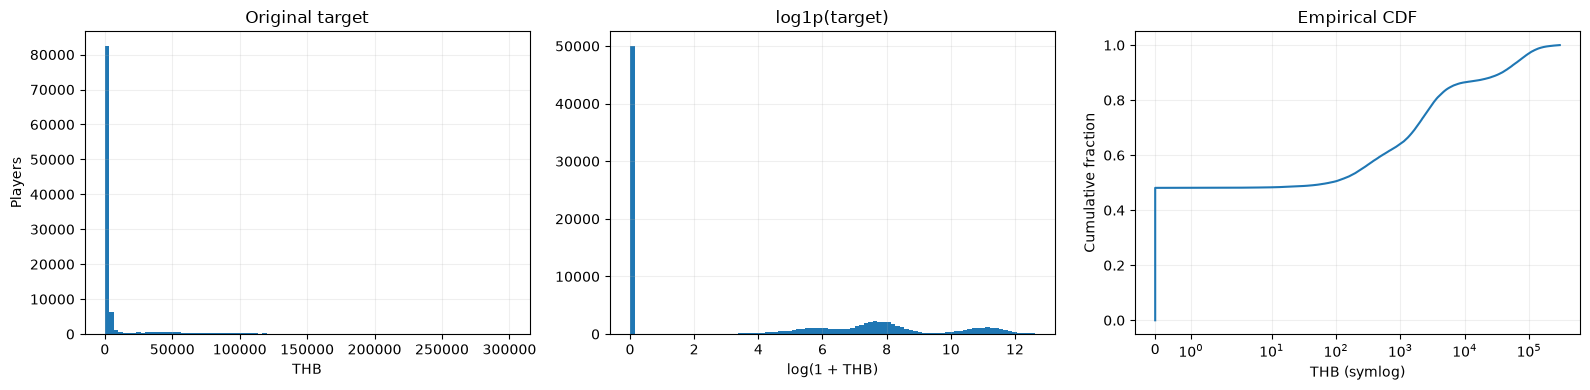

In [6]:
# วาดกราฟการกระจายของ target แล้วบันทึกเป็น target_distribution.png
fig, ax = plt.subplots(1,3,figsize=(16,4))
# รูปซ้าย: ยอดเงินจริง
ax[0].hist(y_all,bins=90); ax[0].set(title='Original target',xlabel='THB',ylabel='Players')
# รูปกลาง: หลังแปลง log(1 + THB) เพื่อดูกลุ่มที่จ่ายเงิน
ax[1].hist(np.log1p(y_all),bins=90); ax[1].set(title='log1p(target)',xlabel='log(1 + THB)')
# รูปขวา: สัดส่วนสะสมของผู้เล่นตามยอดเงิน
ax[2].plot(np.sort(y_all),np.arange(1,len(y_all)+1)/len(y_all)); ax[2].set(xscale='symlog',title='Empirical CDF',xlabel='THB (symlog)',ylabel='Cumulative fraction')
plt.tight_layout(); plt.savefig(FIG/'target_distribution.png',dpi=140); plt.show()

**อธิบายกราฟ `target_distribution.png`:**

- **รูปซ้าย (ยอดจริง):** แท่งที่ 0 สูงกว่าแท่งอื่นมาก แล้วลากหางยาวไปถึง 300,000 บาท ผู้เล่น **48.12%** ใช้จ่าย 0 บาท
- **รูปกลาง (log1p):** กองที่ 0 แยกจากกลุ่มคนที่จ่ายเงินชัดเจน และกลุ่มคนจ่ายเงินเองยังมีหลายยอด (ประมาณ log 6, 8 และ 11 หรือราว 400, 3,000 และ 60,000 บาท) สอดคล้องกับยอดเฉลี่ยที่ต่างกันมากตาม `segment` ในขั้นที่ 4
- **รูปขวา (CDF):** เส้นกระโดดขึ้นเกือบ 0.5 ทันทีที่ 0 บาท median อยู่ที่ **79.44 บาท** ขณะที่ mean สูงถึง **10,497 บาท** และ skewness **4.17**
- ค่าสูงสุด 300,000 บาทมีผู้เล่น 15 คน อาจเป็นเพดานของข้อมูล ส่วนผู้เล่น top 1% สร้างรายได้ **19%** ของทั้งหมด

**สิ่งที่นำไปใช้ต่อ:**
1. ข้อมูลเป็น zero-inflated จึงควรลองแบบ **two-stage** (ทายก่อนว่าจะจ่ายไหม แล้วค่อยทายว่าจ่ายเท่าไร)
2. median ต่ำกว่า mean มาก และ metric เป็น absolute error จึงควรใช้ loss แบบ **L1/median** แทน MSE
3. ไม่ลบ high spenders ทิ้ง เพราะ metric วัดเป็นบาทจริง และกลุ่มนี้มีน้ำหนักต่อคะแนนมาก

### 3.3 คุณภาพข้อมูล

ตรวจสัดส่วนค่าว่างของ train เทียบ test, จำนวนค่าที่ไม่ซ้ำ, ช่วงค่าต่ำสุดถึงสูงสุด, ค่า infinity และแถวที่ซ้ำกัน และแสดงผู้เล่นที่ยอดสูงสุด 12 คนเทียบกับยอดในอดีต

In [7]:
# ตรวจค่าว่าง ค่าผิดปกติ และแถวซ้ำ
quality = pd.DataFrame({'train_missing_rate': train[features].isna().mean(),
                        'test_missing_rate': test[features].isna().mean(),
                        'train_unique': train[features].nunique(),
                        'train_min': train[features].min(), 'train_max': train[features].max()})
display(quality)
# ต้องไม่มีค่า infinity ทั้งใน train และ test
assert not np.isinf(train[features].to_numpy()).any()
assert not np.isinf(test[features].to_numpy()).any()
print('Duplicate feature rows:', train[features].duplicated().sum())
# ดูผู้เล่นที่จ่ายสูงสุดเทียบกับยอดย้อนหลัง
display(train.nlargest(12,TARGET)[[ID,'historical_spending','prev_month_spending','segment',TARGET]])
# บันทึกตารางไว้ใน models/Task3/
target_summary.to_csv(OUT/'target_summary.csv'); quality.to_csv(OUT/'data_quality.csv')

,train_missing_rate,test_missing_rate,train_unique,train_min,train_max
friend_count,0.058490,0.059755,375,0.000000,410.000000
social_interactions,0.058115,0.057360,220,0.000000,230.000000
guild_membership,0.058385,0.057013,2,0.000000,1.000000
event_participation_rate,0.057971,0.058867,97971,10.001794,84.999814
daily_login_streak,0.058721,0.059060,210,0.000000,256.000000
avg_session_length,0.057721,0.055352,97997,20.000851,364.428629
sessions_per_week,0.058952,0.059292,97869,1.000309,47.801941
total_playtime_hours,0.058135,0.059755,97954,50.011704,1980.980365
days_since_last_login,0.058029,0.059098,97965,0.000012,40.914764
achievement_count,0.059500,0.058249,469,0.000000,507.000000


Duplicate feature rows: 0


,player_id,historical_spending,prev_month_spending,segment,spending_30d
327,P022946,137808.726099,52427.908242,3.0,300000.0
4512,P085713,102590.633309,38458.778243,NaN,300000.0
8813,P019448,119313.156073,40641.322872,3.0,300000.0
12130,P048155,NaN,43556.138832,3.0,300000.0
16034,P081657,103902.624689,40275.924030,3.0,300000.0
24436,P046805,96083.357057,35839.828286,3.0,300000.0
27197,P088807,93377.927956,37465.729056,3.0,300000.0
30841,P127713,108681.149677,32904.024197,3.0,300000.0
35952,P079852,117299.529772,39676.208885,3.0,300000.0
52072,P033519,103469.116746,41230.266102,3.0,300000.0


**ผลลัพธ์:** แต่ละ feature มีค่าว่างประมาณ **5.8%** และอัตราใน train กับ test ใกล้กันมาก ไม่พบค่า infinity และไม่มีแถว feature ซ้ำ ผู้เล่นที่จ่ายสูงสุดส่วนใหญ่อยู่ใน `segment` 3 และมี `historical_spending` สูงเกิน 100,000 บาท แต่บางคนมีค่าว่างในยอดย้อนหลัง ซึ่งทำให้ทำนายยากขึ้น

ค่าว่างไม่ได้เติมตรงนี้ แต่ให้แต่ละโมเดลจัดการเอง (tree models รองรับ NaN, ส่วนโมเดลเชิงเส้นเติม median ภายใน pipeline ที่ fit เฉพาะ training fold)

## 4. ความสัมพันธ์กับ target และ distribution shift

### 4.1 Correlation และยอดในอดีตเทียบอนาคต

- **Pearson** วัดความสัมพันธ์เชิงเส้น ซึ่งไวต่อค่าสุดโต่งในหางขวา
- **Spearman** วัดจากอันดับ จึงลดอิทธิพลของหางหนัก

ถ้าสองค่านี้ต่างกันมาก แปลว่าความสัมพันธ์ส่วนหนึ่งมาจากกลุ่มคนจ่ายหนัก จากนั้นวาด scatter ระหว่างยอดย้อนหลังกับยอดอนาคตบนแกน symlog

,pearson,spearman
historical_spending,0.867378,0.651253
prev_month_spending,0.865319,0.651986
segment,0.567305,0.663879
event_participation_rate,0.497777,0.587611
vip_status,0.443448,0.420824
is_premium_member,0.413554,0.402734
total_transactions,0.284200,0.266652
avg_transaction_value,0.265900,0.537750
purchases_on_discount,0.245939,0.233407
owns_limited_edition,0.201004,0.272998


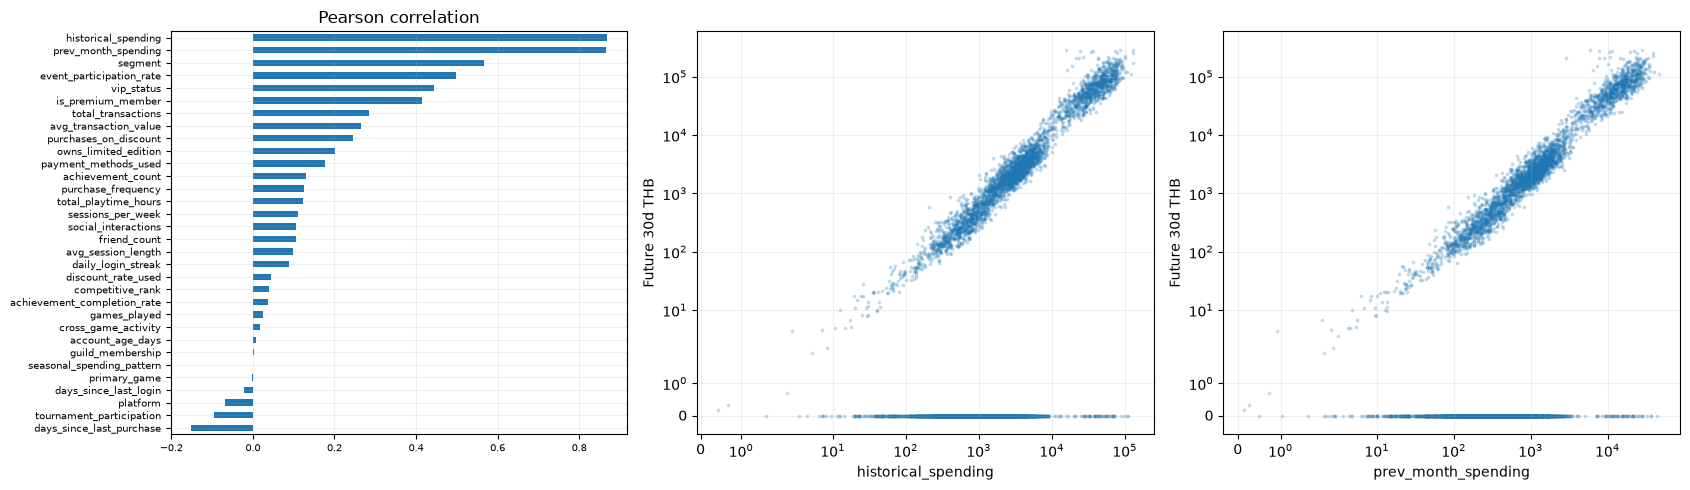

In [8]:
# คำนวณ correlation และวาดกราฟยอดย้อนหลังเทียบยอดอนาคต
corr = pd.DataFrame({'pearson': train[features].corrwith(y_all),
                     'spearman': train[features].corrwith(y_all,method='spearman')}).sort_values('pearson',ascending=False)
display(corr)
fig,ax=plt.subplots(1,3,figsize=(17,5))
# รูปซ้าย: Pearson correlation ของทุก feature
corr.pearson.sort_values().plot.barh(ax=ax[0],fontsize=7,title='Pearson correlation')
# รูปกลางและขวา: scatter ยอดย้อนหลังกับยอดอนาคต (สุ่ม 7,000 แถวให้อ่านกราฟง่าย)
sample=train.sample(7000,random_state=SEED)
for a,c in zip(ax[1:],['historical_spending','prev_month_spending']):
    a.scatter(sample[c],sample[TARGET],s=3,alpha=.2)
    a.set(xscale='symlog',yscale='symlog',xlabel=c,ylabel='Future 30d THB')
plt.tight_layout(); plt.savefig(FIG/'historical_relationships.png',dpi=140); plt.show()

**อธิบายกราฟ `historical_relationships.png`:**

- **รูปซ้าย (Pearson):** `historical_spending` (0.867) และ `prev_month_spending` (0.865) สัมพันธ์กับ target สูงที่สุด ตามด้วย `segment` (0.567) และ `event_participation_rate` (0.498)
- **รูปกลางและขวา (scatter บนแกน log):** ผู้เล่นที่จ่ายเงินเรียงเป็นแถบแคบตามแนวทแยง ยอดย้อนหลังจึงทำนายยอดอนาคตของคนที่จ่ายได้ดีมาก แต่มีแถวจุดที่ 0 บาทยาวตลอดแกนนอนตั้งแต่ยอดย้อนหลังหลักสิบถึงหลักหมื่นบาท แปลว่ามีคนเคยจ่ายจำนวนมากที่เดือนถัดไปไม่จ่ายเลย
- **Spearman ของยอดย้อนหลังอยู่ที่ประมาณ 0.65** ต่ำกว่า Pearson ชัดเจน สาเหตุหลักคือแถวที่เป็น 0 บาทซึ่งเกิดได้กับทุกระดับยอดย้อนหลัง ทำให้อันดับไม่สอดคล้องกัน

**สิ่งที่นำไปใช้ต่อ:** ยอดย้อนหลังเป็นสัญญาณหลักของ "จ่ายเท่าไร" จึงสร้าง features ต่อยอดจากยอดย้อนหลังในขั้นที่ 6 แต่ยอดย้อนหลังบอกไม่ได้ว่าใครจะเป็นศูนย์ ส่วนที่ยากของโจทย์จึงเป็นคำถาม "จะจ่ายไหม" ซึ่งต้องมีโมเดลแยกต่างหาก (two-stage)

### 4.2 ตรวจ train/test shift และยอดตาม segment

ใช้ **Kolmogorov–Smirnov (KS) statistic** เทียบการกระจายของแต่ละ feature ระหว่าง train กับ test พร้อมเทียบสัดส่วนค่าว่าง ถ้า KS สูง แปลว่า test มีหน้าตาต่างจาก train และโมเดลอาจ generalize ได้ไม่ดี

ใช้ test ในขั้นนี้เพื่อตรวจความเข้ากันได้ของข้อมูลเท่านั้น ไม่ได้ใช้เลือก model, feature หรือ threshold

In [9]:
# ตรวจ distribution shift ระหว่าง train/test และสรุปยอดตาม segment
shift_rows=[]
for c in features:
    a,b=train[c].dropna(),test[c].dropna()
    # KS test เทียบการกระจายของ feature ระหว่าง train และ test
    stat=ks_2samp(a,b)
    shift_rows.append({'feature':c,'KS':stat.statistic,'KS_p':stat.pvalue,
                       'missing_rate_difference':test[c].isna().mean()-train[c].isna().mean(),
                       'wasserstein_over_train_std':wasserstein_distance(a,b)/max(a.std(),1e-9)})
shift=pd.DataFrame(shift_rows).sort_values('KS',ascending=False)
display(shift)
# ยอดใช้จ่ายแยกตาม segment (NaN คือไม่ทราบ segment)
display(train.groupby('segment',dropna=False)[TARGET].agg(['count','mean','median','max']))
corr.to_csv(OUT/'correlations.csv'); shift.to_csv(OUT/'train_test_shift.csv',index=False)

,feature,KS,KS_p,missing_rate_difference,wasserstein_over_train_std
18,primary_game,0.010127,0.036152,-0.000754,0.020850
9,achievement_count,0.009081,0.079505,-0.001251,0.012354
7,total_playtime_hours,0.008049,0.158995,0.001620,0.012828
6,sessions_per_week,0.007725,0.193948,0.000340,0.010257
29,competitive_rank,0.007111,0.275767,0.001713,0.014692
11,historical_spending,0.007029,0.288302,0.000143,0.007752
3,event_participation_rate,0.007012,0.291267,0.000896,0.007492
10,achievement_completion_rate,0.006484,0.383577,0.000888,0.009369
15,account_age_days,0.005844,0.514528,-0.001220,0.009167
23,purchase_frequency,0.005709,0.544848,-0.001991,0.007989


,count,mean,median,max
segment,,,,
0.0,39241,73.957917,0.00,2358.07
1.0,24483,944.370547,264.25,10245.50
2.0,19762,2283.845328,1837.64,20127.93
3.0,14579,65357.700960,54760.28,300000.00
NaN,5935,11404.505553,125.56,300000.00


**ผลลัพธ์:**
- KS สูงสุดอยู่ที่ประมาณ **0.010** (`primary_game`) และความต่างของอัตราค่าว่างไม่ถึง 0.2% ทุก feature แปลว่า train กับ test มีการกระจายใกล้กันมาก ผล validation จึงน่าจะสะท้อนผลบน test ได้
- ยอดเฉลี่ยตาม `segment` ต่างกันมาก: segment 0 ≈ 74 บาท, 1 ≈ 944 บาท, 2 ≈ 2,284 บาท และ **segment 3 ≈ 65,358 บาท** ส่วนแถวที่ segment ว่าง (5,935 แถว) มีทั้งคนจ่ายน้อยและคนจ่ายสูงสุด

ข้อจำกัด: KS ที่ต่ำบอกแค่ว่า feature แต่ละตัวกระจายคล้ายกัน ไม่ได้รับประกันว่าความสัมพันธ์ระหว่าง feature กับ target ใน test จะเหมือน train

## 5. ตรวจความเสี่ยง leakage และแบ่งชุดประเมิน

### 5.1 ความเสี่ยง leakage

- `historical_spending`, `prev_month_spending` และ features ด้าน recency เป็นข้อมูลย้อนหลังตาม datacard จึงใช้ได้ แต่ข้อมูลไม่มี timestamp จึงตรวจรายแถวไม่ได้ว่า snapshot เกิดก่อนช่วง 30 วันที่ทำนาย
- `segment` เป็น feature ที่ผู้จัดใส่มาใน Task 3 เอง ใช้ตาม schema โดยไม่ได้ดึง label จาก Task 2 มาเชื่อม
- `player_id` เป็นแค่รหัส จึงไม่ใช้เป็น feature
- การเติมค่าว่างและ scaling ทำใน pipeline ที่ fit เฉพาะ training fold ส่วน feature engineering คำนวณภายในแถวเดียวกัน จึงไม่มีข้อมูลข้ามแถว

### 5.2 แบ่งข้อมูล

| ชุด | สัดส่วน | ใช้ทำอะไร |
|---|---|---|
| `dev_fit` | 68% | ฝึกโมเดลตอนเปรียบเทียบและจูน |
| `dev_validation` | 17% | early stopping และเลือกโมเดลรอบแรก |
| `locked_holdout` | 15% | วัดผลสุดท้ายครั้งเดียว ห้ามใช้ตัดสินใจใด ๆ |

ทุกการแบ่งใช้ **stratify ตามช่วงยอดเงิน** (0, ≤100, ≤500, …, >100,000 บาท) เพื่อให้แต่ละชุดมีสัดส่วนคนจ่าย 0 บาทและคนจ่ายหนักเท่ากัน

In [10]:
# แบ่ง train เป็น dev_fit / dev_validation / locked_holdout
# แบ่งยอดเงินเป็น 8 ช่วงสำหรับ stratified split
def strata(y):
    return pd.cut(np.asarray(y),[-np.inf,0,100,500,2000,10000,50000,100000,np.inf],labels=False)
all_idx=np.arange(len(train))
# กัน locked holdout 15% ออกก่อน แล้วแบ่ง dev ที่เหลือเป็น fit 80% / validation 20%
dev_idx,hold_idx=train_test_split(all_idx,test_size=.15,random_state=SEED,stratify=strata(y_all))
fit_idx,val_idx=train_test_split(dev_idx,test_size=.20,random_state=SEED+1,stratify=strata(y_all.iloc[dev_idx]))
# ยืนยันว่า dev กับ holdout ไม่มีแถวซ้ำกัน
assert not set(dev_idx)&set(hold_idx)
split=pd.DataFrame({'row_index':all_idx,'split':'dev_fit'})
split.loc[val_idx,'split']='dev_validation'; split.loc[hold_idx,'split']='locked_holdout'
split.to_csv(OUT/'validation_split.csv',index=False)
print(split['split'].value_counts())

split
dev_fit           70720
dev_validation    17680
locked_holdout    15600
Name: count, dtype: int64


**ผลลัพธ์:** ได้ `dev_fit` 70,720 แถว, `dev_validation` 17,680 แถว และ `locked_holdout` 15,600 แถว และบันทึกเลขแถวของแต่ละชุดไว้ใน `models/Task3/validation_split.csv` เพื่อให้ตรวจสอบย้อนหลังได้

## 6. Feature engineering

### 6.1 ฟังก์ชันช่วยหารอย่างปลอดภัย

`safe_ratio(a, b)` หาร `a` ด้วย `b` เฉพาะเมื่อ `b > 0` ถ้าตัวหารเป็น 0 หรือติดลบจะได้ NaN แทน infinity แล้วปล่อยให้โมเดลจัดการ NaN เอง

In [11]:
# กำหนดคอลัมน์หมวดหมู่และฟังก์ชันหารที่ไม่สร้าง infinity
CATEGORICAL=['primary_game','platform','segment','seasonal_spending_pattern']
def safe_ratio(a,b):
    return a/b.where(b>0)

### 6.2 สร้าง features ใหม่

`make_features(df, engineered=False)` คืน 32 features เดิม ถ้าตั้ง `engineered=True` จะเพิ่ม features อีก 30 ตัวที่คำนวณจากข้อมูลในแถวเดียวกันเท่านั้น (ไม่ใช้ target) แบ่งเป็นกลุ่มดังนี้

| กลุ่ม | ตัวอย่าง | เหตุผล |
|---|---|---|
| ยอดซื้อสร้างใหม่ | `reconstructed_history = total_transactions × avg_transaction_value`, `history_with_transaction_fallback` | ใช้แทน `historical_spending` เมื่อค่านี้หายไป |
| Ratio | `previous_month_share_of_history`, `lifetime_spending_per_day`, `discount_purchase_share` | ปรับขนาดให้เทียบกันได้ระหว่างผู้เล่นที่อายุบัญชีต่างกัน |
| Interaction | `vip_spending_interaction`, `premium_spending_interaction`, `event_spending_interaction` | ยอดล่าสุดของ VIP/premium อาจมีความหมายต่างจากผู้เล่นทั่วไป |
| Recency | `purchase_recency_frequency`, `login_purchase_recency_gap` | ซื้อล่าสุดเมื่อไรเทียบกับ login ล่าสุด |
| Seasonality | `season_sin`, `season_cos` | แปลงเดือนเป็นวงกลม ให้เดือน 12 อยู่ติดกับเดือน 1 |
| Log | `log1p_historical_spending` ฯลฯ | ลดอิทธิพลของหางหนัก |
| อื่น ๆ | `missing_count`, `history_discrepancy` | จำนวนค่าว่างในแถว และความต่างระหว่างยอดจริงกับยอดสร้างใหม่ |

ไม่ทราบว่า `historical_spending` สะสมมากี่เดือน จึงไม่ได้สมมติว่าเป็นค่าเฉลี่ยรายเดือน และใช้ค่าต่อ transaction หรือต่อวันแทน

In [12]:
# ฟังก์ชันสร้าง features ดิบและ features ที่ออกแบบเพิ่ม
def make_features(df,engineered=False):
    x=df[features].copy()
    if engineered:
        # จำนวน features ที่ว่างในแถวนี้
        x['missing_count']=x.isna().sum(axis=1)
        h,p=x.historical_spending,x.prev_month_spending
        n,age=x.total_transactions,x.account_age_days
        # ยอดซื้อสร้างใหม่จาก จำนวนครั้ง × มูลค่าเฉลี่ย (ใช้เติมเมื่อ historical_spending หาย)
        reconstructed=n*x.avg_transaction_value
        x['reconstructed_history']=reconstructed
        x['history_with_transaction_fallback']=h.fillna(reconstructed)
        # ratio features
        x['historical_average_per_transaction']=safe_ratio(h,n)
        x['previous_month_share_of_history']=safe_ratio(p,h)
        x['previous_month_per_transaction']=safe_ratio(p,n)
        x['spending_per_recent_session']=safe_ratio(p,x.sessions_per_week*30/7)
        x['lifetime_spending_per_day']=safe_ratio(h,age)
        x['lifetime_spending_30d_proxy']=safe_ratio(h,age)*30
        x['transactions_per_account_day']=safe_ratio(n,age)
        x['spending_per_play_hour']=safe_ratio(h,x.total_playtime_hours)
        # พฤติกรรมการเล่นและ interaction กับยอดใช้จ่าย
        x['recent_play_minutes']=x.avg_session_length*x.sessions_per_week
        x['event_engagement']=x.event_participation_rate*x.sessions_per_week
        x['event_spending_interaction']=x.event_participation_rate*p
        x['premium_spending_interaction']=x.is_premium_member*p
        x['vip_spending_interaction']=x.vip_status*p
        x['social_activity_interaction']=x.social_interactions*x.friend_count
        x['social_activity_per_session']=safe_ratio(x.social_interactions,x.sessions_per_week)
        # สัดส่วนการซื้อช่วงลดราคาและ recency ของการซื้อ
        x['discount_purchase_share']=safe_ratio(x.purchases_on_discount,n)
        x['purchase_recency_frequency']=safe_ratio(x.purchase_frequency,x.days_since_last_purchase+1)
        x['login_purchase_recency_gap']=x.days_since_last_purchase-x.days_since_last_login
        x['purchase_login_recency_ratio']=safe_ratio(x.days_since_last_purchase+1,x.days_since_last_login+1)
        # แปลงเดือนเป็นพิกัดบนวงกลม
        month=x.seasonal_spending_pattern
        x['season_sin']=np.sin(2*np.pi*(month-1)/12)
        x['season_cos']=np.cos(2*np.pi*(month-1)/12)
        # log ของยอดเงินและจำนวนที่เบ้มาก
        for c in ['historical_spending','prev_month_spending','avg_transaction_value','total_transactions','days_since_last_purchase']:
            x['log1p_'+c]=np.log1p(x[c].clip(lower=0))
        # Redundant signal recovery: deterministic row-local identity, never use y.
        x['history_discrepancy']=h-reconstructed
    # แปลง infinity ที่อาจเหลือเป็น NaN
    return x.replace([np.inf,-np.inf],np.nan).astype('float64')

In [13]:
# สร้างชุด features ของ train ทั้งแบบดิบและแบบ engineered
X_raw=make_features(train)
X_fe=make_features(train,True)
# test จะสร้าง features เมื่อถึงขั้น final prediction หลังเลือกโมเดลแล้ว
print('Raw:',X_raw.shape,'Engineered:',X_fe.shape)
print('New features:',sorted(set(X_fe)-set(X_raw)))

Raw: (104000, 32) Engineered: (104000, 62)
New features: ['discount_purchase_share', 'event_engagement', 'event_spending_interaction', 'historical_average_per_transaction', 'history_discrepancy', 'history_with_transaction_fallback', 'lifetime_spending_30d_proxy', 'lifetime_spending_per_day', 'log1p_avg_transaction_value', 'log1p_days_since_last_purchase', 'log1p_historical_spending', 'log1p_prev_month_spending', 'log1p_total_transactions', 'login_purchase_recency_gap', 'missing_count', 'premium_spending_interaction', 'previous_month_per_transaction', 'previous_month_share_of_history', 'purchase_login_recency_ratio', 'purchase_recency_frequency', 'recent_play_minutes', 'reconstructed_history', 'season_cos', 'season_sin', 'social_activity_interaction', 'social_activity_per_session', 'spending_per_play_hour', 'spending_per_recent_session', 'transactions_per_account_day', 'vip_spending_interaction']


**ผลลัพธ์:** แบบดิบได้ 32 คอลัมน์ ส่วนแบบ engineered ได้ 62 คอลัมน์ (เพิ่ม 30 ตัว) ขั้นที่ 8 จะวัดว่า features ที่เพิ่มช่วยลด error ได้จริงหรือไม่ เพราะการเพิ่ม feature อาจทำให้แย่ลงก็ได้

## 7. โมเดลที่นำมาเปรียบเทียบ

### 7.1 คลาส `Candidate` สำหรับรวมทุกโมเดลไว้ในรูปแบบเดียวกัน

ทุกโมเดลมี `fit()` และ `predict()` แบบเดียวกัน จึงเปรียบเทียบด้วย split เดียวกันได้ง่าย โมเดลที่รองรับมีดังนี้

| กลุ่ม | โมเดล | หมายเหตุ |
|---|---|---|
| Baseline | Dummy (median) | ทายค่า median ทุกแถว เป็นเกณฑ์ขั้นต่ำ |
| เชิงเส้น | Ridge, ElasticNet | เติม median + missing indicator + StandardScaler ใน pipeline |
| Bagging | Random Forest, Extra Trees | รองรับ NaN โดยตรง |
| Boosting | LightGBM, XGBoost, CatBoost | เน้น L1 (MAE) loss ตรงกับ metric |
| Log target | LightGBM บน `log1p(y)` | แปลงกลับด้วย `expm1` ก่อนวัดผลเป็นบาท |
| Tweedie | LightGBM Tweedie | loss ที่ออกแบบมาสำหรับ target ที่ไม่ติดลบและมีศูนย์ |
| **Two-stage** | classifier + regressor | ดูคำอธิบายด้านล่าง |

**Two-stage (zero-inflated model)** แยกเป็นสองคำถาม
1. **จะจ่ายไหม:** `LGBMClassifier` ทำนายความน่าจะเป็น $p$ ที่ผู้เล่นจะจ่ายมากกว่า 0 บาท
2. **ถ้าจ่ายจะจ่ายเท่าไร:** ฝึก regressor เฉพาะแถวที่จ่ายจริง

รวมผลได้ 2 แบบ
- `two_gamma`: $p \times$ ค่าเฉลี่ยจาก Gamma regression เหมาะกับการคาดรายได้รวม
- `two_median` (**mixture median**): เหมาะกับ MAE เพราะ MAE ดีที่สุดเมื่อทายค่า median ถ้า $p \le 0.5$ ทาย 0 บาท ถ้าไม่ใช่จะทาย quantile ที่ระดับ $1 - 0.5/p$ ของยอดเงิน ซึ่งเป็น median ของการแจกแจงผสมพอดี โดย interpolate จาก quantile regressors 5 ระดับ (0.05, 0.15, 0.30, 0.50, 0.70)

In [14]:
# คลาส Candidate: ห่อทุกโมเดลให้มี fit/predict แบบเดียวกัน
# ค่าเริ่มต้นของ LightGBM ที่ใช้ร่วมกันหลายโมเดล
LGB_BASE=dict(verbosity=-1,n_jobs=THREADS,random_state=SEED,learning_rate=.04,
              n_estimators=1800,num_leaves=31,min_child_samples=80,colsample_bytree=.9,
              reg_lambda=5.0,subsample=.85,subsample_freq=1)
class Candidate:
    def __init__(self,kind,fe=False,params=None,transform=None,upper_clip=False):
        self.kind,self.fe,self.params,self.transform,self.upper_clip=kind,fe,params or {},transform,upper_clip
    # ฝึกโมเดล: แปลง target เป็น log ถ้ากำหนด transform และใช้ eval_set ทำ early stopping
    def fit(self,x,y,eval_set=None,rounds=None):
        self.cap_=float(np.max(y)) if self.upper_clip else np.inf
        yt=np.log1p(y) if self.transform else np.asarray(y)
        ev=None if eval_set is None else (eval_set[0],np.log1p(eval_set[1]) if self.transform else np.asarray(eval_set[1]))
        p=self.params.copy()
        # ---- สร้างโมเดลตามชนิด ----
        if self.kind=='dummy': self.model=DummyRegressor(strategy='median')
        elif self.kind in ['ridge','elastic']:
            reg=Ridge(alpha=100) if self.kind=='ridge' else ElasticNet(alpha=3,l1_ratio=.1,max_iter=4000,tol=.002)
            self.model=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),StandardScaler(),reg)
        elif self.kind in ['rf','et']:
            cls=RandomForestRegressor if self.kind=='rf' else ExtraTreesRegressor
            self.model=cls(n_estimators=160,max_depth=22,min_samples_leaf=8,max_features=.85,n_jobs=THREADS,random_state=SEED)
        elif self.kind=='lgb':
            q={**LGB_BASE,**p}
            if rounds: q['n_estimators']=rounds
            self.model=LGBMRegressor(**q)
        elif self.kind=='xgb':
            q=dict(n_estimators=1400,max_depth=5,learning_rate=.04,objective='reg:absoluteerror',
                   tree_method='hist',subsample=.85,colsample_bytree=.9,reg_lambda=10,n_jobs=THREADS,random_state=SEED)
            q.update(p)
            if rounds:q['n_estimators']=rounds
            if ev is not None:q['early_stopping_rounds']=100
            self.model=XGBRegressor(**q)
        elif self.kind=='cat':
            q=dict(iterations=1800,depth=6,learning_rate=.045,loss_function='MAE',eval_metric='MAE',
                   l2_leaf_reg=10,random_seed=SEED,thread_count=THREADS,verbose=False,allow_writing_files=False)
            q.update(p)
            if rounds:q['iterations']=rounds
            self.model=CatBoostRegressor(**q)
        # ---- two-stage: classifier (จ่าย/ไม่จ่าย) + regressor บนแถวที่จ่ายจริง ----
        elif self.kind in ['two_gamma','two_median']:
            pos=np.asarray(y)>0
            self.classifier=LGBMClassifier(**{**LGB_BASE,'n_estimators':600,'num_leaves':15,'min_child_samples':120})
            self.classifier.fit(x,pos)
            self.quantiles=np.array([.05,.15,.3,.5,.7])
            self.positive=[]
            objs=[{'objective':'gamma'}] if self.kind=='two_gamma' else [{'objective':'quantile','alpha':float(a)} for a in self.quantiles]
            for objective in objs:
                model=LGBMRegressor(**{**LGB_BASE,'n_estimators':900,'num_leaves':23,**objective})
                model.fit(x.loc[pos],np.asarray(y)[pos]); self.positive.append(model)
            self.best_rounds_=900
            return self
        else: raise ValueError(self.kind)
        # ---- ฝึกโมเดล boosting พร้อม early stopping 100 รอบ แล้วจำจำนวนรอบที่ดีที่สุด ----
        if self.kind=='lgb':
            kw={} if ev is None else {'eval_set':[ev],'eval_metric':'mae','callbacks':[lgb.early_stopping(100,verbose=False)]}
            self.model.fit(x,yt,**kw)
            self.best_rounds_=self.model.best_iteration_ or self.model.n_estimators
        elif self.kind=='xgb':
            self.model.fit(x,yt,eval_set=None if ev is None else [ev],verbose=False)
            self.best_rounds_=self.model.best_iteration+1 if ev is not None else self.model.n_estimators
        elif self.kind=='cat':
            # CatBoost treats numeric NaN natively; categorical codes remain numeric for fairness.
            self.model.fit(x,yt,eval_set=ev,early_stopping_rounds=100 if ev is not None else None,verbose=False)
            self.best_rounds_=self.model.tree_count_
        else:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always'); self.model.fit(x,yt)
            if caught: print(self.kind,'warnings:',*[str(w.message)[:160] for w in caught[:2]])
            self.best_rounds_=None
        return self
    # ทำนาย: two-stage รวมความน่าจะเป็นกับยอดเงิน ส่วนโมเดลอื่นแปลงกลับจาก log ถ้าจำเป็น
    def predict(self,x):
        if self.kind.startswith('two_'):
            prob=self.classifier.predict_proba(x)[:,1]
            positive=np.column_stack([m.predict(x) for m in self.positive])
            if self.kind=='two_gamma': pred=prob*positive[:,0]
            else:
                # Sort each row to repair crossing quantiles before interpolation.
                positive=np.sort(np.maximum(positive,0),axis=1)
                q=np.clip(1-.5/np.maximum(prob,1e-8),self.quantiles[0],self.quantiles[-1])
                j=np.clip(np.searchsorted(self.quantiles,q,side='right')-1,0,len(self.quantiles)-2)
                w=(q-self.quantiles[j])/(self.quantiles[j+1]-self.quantiles[j])
                pred=(1-w)*positive[np.arange(len(x)),j]+w*positive[np.arange(len(x)),j+1]
                pred=np.where(prob<=.5,0,pred)
        else:
            pred=self.model.predict(x)
            if self.transform: pred=np.expm1(np.clip(pred,-30,30))
        # ยอดเงินต้องไม่ติดลบ
        return np.clip(np.asarray(pred,dtype=float),0,self.cap_)

### 7.2 ฟังก์ชันคะแนน

- `nmae_score()` คำนวณ NMAE ตามสูตรทางการ พร้อมตรวจว่าข้อมูลถูกรูปแบบ
- `metrics()` รายงาน NMAE, MAE, RMSE และ R² พร้อมกัน แต่ใช้ **MAE** เป็นเกณฑ์เลือกโมเดลเพียงตัวเดียว ส่วน RMSE และ R² ใช้ประกอบการอ่านผลเท่านั้น

In [15]:
# ฟังก์ชันคำนวณ NMAE ตามสูตรทางการ และ metrics อื่นสำหรับรายงาน
def nmae_score(y_true, y_pred):
    y = np.asarray(y_true, dtype=float)
    p = np.asarray(y_pred, dtype=float)
    if y.ndim != 1 or p.shape != y.shape or not len(y):
        raise ValueError('Actuals and predictions must be nonempty matching vectors.')
    if not np.isfinite(y).all() or not np.isfinite(p).all() or (y < 0).any():
        raise ValueError('Expected finite values and nonnegative actual spending.')
    total = float(y.sum())
    if total <= 0:
        raise ValueError('Slide NMAE is undefined when sum(actual spending) is zero.')
    return float(1 / (1 + np.abs(y - p).sum() / total))

def metrics(y,p):
    assert np.isfinite(p).all()
    return {'NMAE':nmae_score(y,p),'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'R2':r2_score(y,p)}

### 7.3 รายการโมเดลที่ทดลอง

กำหนด 17 candidates ชื่อบอกชนิดโมเดล ชุด features (`raw` หรือ `fe`) และ loss ที่ใช้ รวมถึงแบบ `upper_clip` ที่จำกัดคำทำนายไม่ให้เกินค่าสูงสุดใน train

In [16]:
# กำหนดโมเดลทั้ง 17 แบบที่จะเปรียบเทียบ
specs={
 'dummy_median':Candidate('dummy'),
 'ridge_raw':Candidate('ridge'), 'elasticnet_raw':Candidate('elastic'),
 'random_forest_raw':Candidate('rf'), 'extra_trees_raw':Candidate('et'),
 'lightgbm_raw_l1':Candidate('lgb',params={'objective':'regression_l1'}),
 'xgboost_raw_l1':Candidate('xgb'), 'catboost_raw_l1':Candidate('cat'),
 'lightgbm_fe_l1':Candidate('lgb',True,{'objective':'regression_l1'}),
 'catboost_fe_l1':Candidate('cat',True),
 'lightgbm_fe_log_l1':Candidate('lgb',True,{'objective':'regression_l1'},transform='log1p'),
 'lightgbm_fe_log_l2':Candidate('lgb',True,{'objective':'regression'},transform='log1p'),
 'lightgbm_fe_tweedie':Candidate('lgb',True,{'objective':'tweedie','tweedie_variance_power':1.4}),
 'lightgbm_fe_quantile50':Candidate('lgb',True,{'objective':'quantile','alpha':.5}),
 'two_stage_gamma':Candidate('two_gamma',True),
 'two_stage_mixture_median':Candidate('two_median',True),
 'lightgbm_fe_l1_upper_clip':Candidate('lgb',True,{'objective':'regression_l1'},upper_clip=True),
}

### 7.4 ฝึกและวัดผลทุกโมเดลบน dev split เดียวกัน

`benchmark()` ฝึกบน `dev_fit` ใช้ `dev_validation` ทำ early stopping แล้ววัดผลบน `dev_validation` และบันทึกเวลาที่ใช้ ทุกโมเดลใช้แถวชุดเดียวกัน จึงเทียบกันได้ตรง ๆ

In [17]:
# ฝึกและวัดผลทุก candidate บน dev_validation
results=[]; fitted={}; val_preds={}
def benchmark(name,spec):
    x=X_fe if spec.fe else X_raw
    model=copy.deepcopy(spec); start=time.perf_counter()
    model.fit(x.iloc[fit_idx],y_all.iloc[fit_idx],eval_set=(x.iloc[val_idx],y_all.iloc[val_idx]))
    pred=model.predict(x.iloc[val_idx])
    result={'model':name,**metrics(y_all.iloc[val_idx],pred),'seconds':time.perf_counter()-start,
            'best_rounds':model.best_rounds_,'engineered':spec.fe}
    results.append(result); fitted[name]=model; val_preds[name]=pred
    pd.DataFrame(results).sort_values('MAE').to_csv(OUT/'development_benchmarks.csv',index=False)
    print(f"{name:34s} MAE={result['MAE']:,.3f} RMSE={result['RMSE']:,.3f} R2={result['R2']:.4f} seconds={result['seconds']:.1f}",flush=True)
# รันทุกโมเดลแล้วเรียงผลตาม MAE
for name,spec in specs.items(): benchmark(name,spec)
baseline_table=pd.DataFrame(results).sort_values('MAE')
display(baseline_table)

dummy_median                       MAE=10,502.361 RMSE=32,545.694 R2=-0.1143 seconds=0.0


ridge_raw                          MAE=5,029.145 RMSE=15,888.096 R2=0.7344 seconds=0.4


elasticnet_raw                     MAE=9,067.768 RMSE=20,899.972 R2=0.5405 seconds=0.5


random_forest_raw                  MAE=3,244.750 RMSE=13,930.686 R2=0.7958 seconds=35.1


extra_trees_raw                    MAE=3,267.433 RMSE=13,982.145 R2=0.7943 seconds=9.7


lightgbm_raw_l1                    MAE=2,970.315 RMSE=13,786.840 R2=0.8000 seconds=6.3


... (8 outputs left out)

two_stage_gamma                    MAE=2,955.419 RMSE=13,498.274 R2=0.8083 seconds=4.8


two_stage_mixture_median           MAE=2,865.084 RMSE=13,596.500 R2=0.8055 seconds=15.8


lightgbm_fe_l1_upper_clip          MAE=2,902.796 RMSE=13,589.662 R2=0.8057 seconds=9.0


,model,NMAE,MAE,RMSE,R2,seconds,best_rounds,engineered
15,two_stage_mixture_median,0.785693,2865.084336,13596.500308,0.805518,15.750752,900.0,True
8,lightgbm_fe_l1,0.783483,2902.795678,13589.661941,0.805714,9.411787,1796.0,True
13,lightgbm_fe_quantile50,0.783483,2902.795678,13589.661941,0.805714,9.308657,1796.0,True
16,lightgbm_fe_l1_upper_clip,0.783483,2902.795678,13589.661941,0.805714,9.030644,1796.0,True
9,catboost_fe_l1,0.781202,2941.942043,13625.154258,0.804697,22.915220,1478.0,True
14,two_stage_gamma,0.780420,2955.418997,13498.274220,0.808318,4.796376,900.0,True
6,xgboost_raw_l1,0.780360,2956.452923,13746.601873,0.801200,13.575179,1399.0,False
5,lightgbm_raw_l1,0.779557,2970.314805,13786.839917,0.800035,6.291190,1799.0,False
10,lightgbm_fe_log_l1,0.778100,2995.536870,13879.417667,0.797340,1.917051,201.0,True
12,lightgbm_fe_tweedie,0.777449,3006.847214,13527.455584,0.807488,1.826307,196.0,True


**ผลลัพธ์ (MAE บน dev_validation หน่วยบาท ยิ่งต่ำยิ่งดี):**

| โมเดล | MAE | R² |
|---|---|---|
| dummy_median | 10,502 | −0.114 |
| ridge_raw | 5,029 | 0.734 |
| elasticnet_raw | 9,068 | 0.541 |
| random_forest_raw | 3,245 | 0.796 |
| lightgbm_raw_l1 | 2,970 | 0.800 |
| xgboost_raw_l1 | 2,956 | 0.801 |
| lightgbm_fe_l1 | 2,903 | 0.806 |
| lightgbm_fe_log_l1 | 2,996 | 0.797 |
| lightgbm_fe_log_l2 | 6,578 | 0.513 |
| lightgbm_fe_tweedie | 3,007 | 0.808 |
| two_stage_gamma | 2,955 | 0.808 |
| **two_stage_mixture_median** | **2,865** | 0.806 |

- Boosting ด้วย L1 loss ดีกว่าโมเดลเชิงเส้นและ bagging ชัดเจน
- **Two-stage mixture median ดีที่สุด** ตรงกับที่ EDA ชี้ว่าข้อมูลเป็น zero-inflated
- `lightgbm_fe_log_l2` แย่มาก เพราะ MSE บน log scale ทำให้ทายใกล้ค่าเฉลี่ยเรขาคณิต พอแปลงกลับจึงทายต่ำกว่าจริงมาก เป็นหลักฐานว่าต้องวัดผลหลัง inverse transform เป็นบาทเสมอ
- Tweedie กับ two_stage_gamma ได้ R² สูง แต่ MAE แย่กว่า เพราะ loss ทั้งสองเน้นค่าเฉลี่ย ไม่ใช่ median
- `quantile50` และ `upper_clip` ได้ผลเท่ากับ `lightgbm_fe_l1` พอดี (quantile 0.5 คือ L1 และคำทำนายไม่เคยเกินเพดาน)

## 8. ผลของ feature engineering และ two-stage classifier

ส่วนนี้เทียบโมเดลเดียวกันก่อนและหลังเพิ่ม engineered features บน split เดียวกัน และวัดคุณภาพของ classifier ในส่วน "จะจ่ายไหม" แยกต่างหาก ด้วย AUC (แยกคนจ่ายกับไม่จ่ายได้ดีแค่ไหน) และ Brier score (ความน่าจะเป็นแม่นแค่ไหน ยิ่งต่ำยิ่งดี)

In [18]:
# เทียบ MAE ก่อน/หลัง feature engineering และวัด AUC ของ spender classifier
pairs=[('lightgbm_raw_l1','lightgbm_fe_l1'),('catboost_raw_l1','catboost_fe_l1')]
comparison=[]
for raw,fe in pairs:
    a=next(r['MAE'] for r in results if r['model']==raw); b=next(r['MAE'] for r in results if r['model']==fe)
    comparison.append({'raw':raw,'FE':fe,'MAE_before':a,'MAE_after':b,'improvement_THB':a-b})
display(pd.DataFrame(comparison))
# วัดคุณภาพของ classifier ใน two-stage
for name in ['two_stage_gamma','two_stage_mixture_median']:
    prob=fitted[name].classifier.predict_proba(X_fe.iloc[val_idx])[:,1]
    print(name,'spender AUC:',roc_auc_score(y_all.iloc[val_idx]>0,prob),'Brier:',brier_score_loss(y_all.iloc[val_idx]>0,prob))
pd.DataFrame(comparison).to_csv(OUT/'feature_engineering_comparison.csv',index=False)

,raw,FE,MAE_before,MAE_after,improvement_THB
0,lightgbm_raw_l1,lightgbm_fe_l1,2970.314805,2902.795678,67.519127
1,catboost_raw_l1,catboost_fe_l1,3225.443730,2941.942043,283.501686


two_stage_gamma spender AUC: 0.7870935228145759 Brier: 0.1860933811776866


two_stage_mixture_median spender AUC: 0.7870935228145759 Brier: 0.1860933811776866


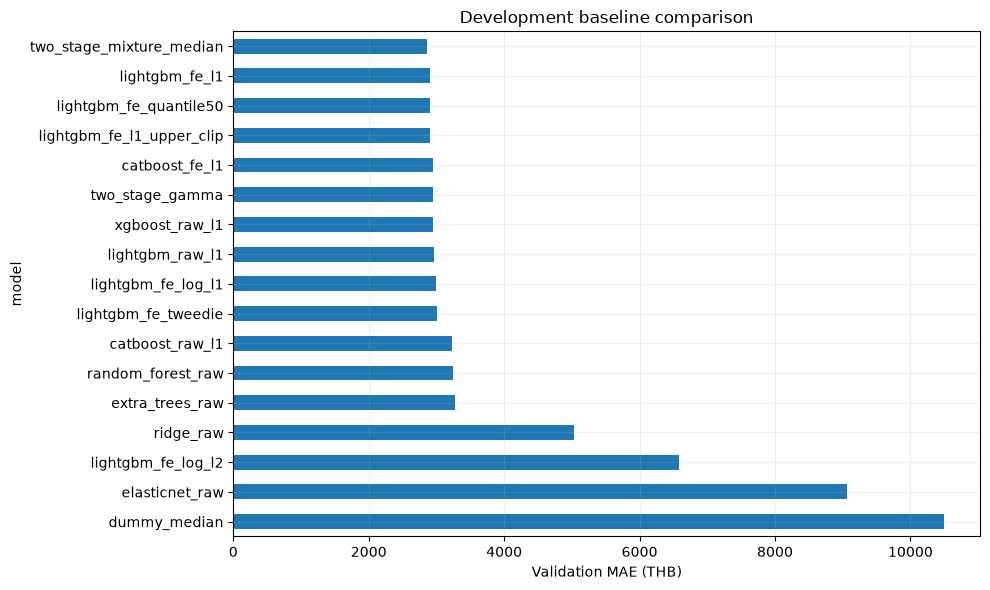

In [19]:
# วาดกราฟแท่งเปรียบเทียบ MAE ของทุกโมเดล แล้วบันทึกเป็น baseline_comparison.png
fig,ax=plt.subplots(figsize=(10,6))
baseline_table.sort_values('MAE',ascending=False).plot.barh(x='model',y='MAE',ax=ax,legend=False)
ax.set(xlabel='Validation MAE (THB)',title='Development baseline comparison')
plt.tight_layout(); plt.savefig(FIG/'baseline_comparison.png',dpi=140); plt.show()

**อธิบายกราฟ `baseline_comparison.png`:** แกนนอนคือ MAE บน dev_validation (บาท) แท่งยิ่งสั้นยิ่งดี โมเดลที่ดีที่สุดอยู่บนสุด และ dummy อยู่ล่างสุด (กราฟนี้วาดก่อนขั้น Optuna จึงยังไม่มี `lightgbm_optuna_l1`)

- Dummy ทาย median ทุกคนได้ MAE ประมาณ 10,500 บาท ส่วน two-stage mixture median ลดลงเหลือ 2,865 บาท (**ลดลงประมาณ 73%**)
- แท่งของโมเดล boosting และ two-stage ยาวใกล้กันมาก (2,865–3,007 บาท) ต่างจาก Ridge และ ElasticNet ที่ยาวกว่าชัดเจน ความสัมพันธ์จึงไม่ใช่เชิงเส้น

**ผลของ feature engineering:**
- LightGBM: MAE 2,970 → 2,903 บาท (**ลดลง 67.5 บาท**)
- CatBoost: MAE 3,225 → 2,942 บาท (**ลดลง 283.5 บาท**)

Features ที่ออกแบบช่วยทั้งสองโมเดล จึงใช้ชุด engineered ต่อในขั้นถัดไป

**Spender classifier:** AUC **0.787** และ Brier **0.186** แยกคนจ่ายกับไม่จ่ายได้ปานกลาง จุดนี้เป็นข้อจำกัดหลักของ two-stage เพราะถ้าทายผิดว่าคนจะจ่าย error จะเท่ากับยอดที่ทายทั้งหมด

## 9. จูน hyperparameters ด้วย Optuna

ใช้ Optuna (TPE sampler, 20 trials) จูน LightGBM L1 โดยให้การเลือกชุด features (raw หรือ engineered) อยู่ใน search space ด้วย จูน learning rate, จำนวนใบ, ขนาดใบขั้นต่ำ, การสุ่มคอลัมน์และแถว, regularization และ `max_bin`

ทุก trial ฝึกบน `dev_fit` ใช้ early stopping และวัด MAE บน `dev_validation` เท่านั้น ไม่แตะ locked holdout

ข้อควรระวัง: best trial ถูกเลือกจาก split เดียว คะแนนจึงดีเกินจริงเล็กน้อย (optimistic bias) ขั้นที่ 10 จึงต้องตรวจซ้ำด้วย cross-validation

In [20]:
# ฟังก์ชัน objective ของ Optuna: คืนค่า MAE ที่ต้องการให้ต่ำที่สุด
def objective(trial):
    fe=trial.suggest_categorical('engineered',[False,True])
    # search space ของ hyperparameters
    params={'objective':'regression_l1','n_estimators':2200,
      'learning_rate':trial.suggest_float('learning_rate',.018,.085,log=True),
      'num_leaves':trial.suggest_int('num_leaves',12,63),
      'min_child_samples':trial.suggest_int('min_child_samples',40,350,log=True),
      'colsample_bytree':trial.suggest_float('colsample_bytree',.65,1),
      'subsample':trial.suggest_float('subsample',.7,1),
      'reg_alpha':trial.suggest_float('reg_alpha',.001,50,log=True),
      'reg_lambda':trial.suggest_float('reg_lambda',.01,100,log=True),
      'max_bin':trial.suggest_categorical('max_bin',[127,255,511])}
    x=X_fe if fe else X_raw
    # ฝึกบน dev_fit และวัด MAE บน dev_validation
    model=Candidate('lgb',fe,params)
    model.fit(x.iloc[fit_idx],y_all.iloc[fit_idx],eval_set=(x.iloc[val_idx],y_all.iloc[val_idx]))
    score=mean_absolute_error(y_all.iloc[val_idx],model.predict(x.iloc[val_idx]))
    trial.set_user_attr('best_rounds',int(model.best_rounds_))
    print(f'Trial {trial.number:02d}: MAE={score:,.3f}, FE={fe}, rounds={model.best_rounds_}',flush=True)
    return score

In [21]:
# รัน Optuna 20 trials แล้วเพิ่มโมเดลที่ดีที่สุดเข้าตารางเปรียบเทียบ
study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective,n_trials=N_TRIALS,gc_after_trial=True)
study.trials_dataframe().to_csv(OUT/'optuna_trials.csv',index=False)
# สร้าง candidate ใหม่จาก best params แล้ววัดผลแบบเดียวกับโมเดลอื่น
best_params=study.best_params.copy(); use_fe=best_params.pop('engineered')
specs['lightgbm_optuna_l1']=Candidate('lgb',use_fe,{'objective':'regression_l1','n_estimators':2200,**best_params})
benchmark('lightgbm_optuna_l1',specs['lightgbm_optuna_l1'])
print('Best dev-only params:',study.best_params)
display(pd.DataFrame(results).sort_values('MAE'))

Trial 00: MAE=2,948.576, FE=True, rounds=2200


Trial 01: MAE=2,979.142, FE=False, rounds=2200


Trial 02: MAE=2,920.746, FE=True, rounds=1946


Trial 03: MAE=2,936.289, FE=True, rounds=2192


Trial 04: MAE=2,885.654, FE=True, rounds=2185


Trial 05: MAE=2,993.517, FE=False, rounds=2192


... (13 outputs left out)

Trial 19: MAE=2,877.254, FE=True, rounds=1763


lightgbm_optuna_l1                 MAE=2,872.873 RMSE=13,555.513 R2=0.8067 seconds=23.9


Best dev-only params: {'engineered': True, 'learning_rate': 0.02444601900891129, 'num_leaves': 61, 'min_child_samples': 73, 'colsample_bytree': 0.8708656134137285, 'subsample': 0.7595440844820583, 'reg_alpha': 0.0011853452105852257, 'reg_lambda': 0.026563516033398103, 'max_bin': 511}


,model,NMAE,MAE,RMSE,R2,seconds,best_rounds,engineered
15,two_stage_mixture_median,0.785693,2865.084336,13596.500308,0.805518,15.750752,900.0,True
17,lightgbm_optuna_l1,0.785235,2872.872505,13555.512715,0.806689,23.858706,2187.0,True
13,lightgbm_fe_quantile50,0.783483,2902.795678,13589.661941,0.805714,9.308657,1796.0,True
8,lightgbm_fe_l1,0.783483,2902.795678,13589.661941,0.805714,9.411787,1796.0,True
16,lightgbm_fe_l1_upper_clip,0.783483,2902.795678,13589.661941,0.805714,9.030644,1796.0,True
9,catboost_fe_l1,0.781202,2941.942043,13625.154258,0.804697,22.915220,1478.0,True
14,two_stage_gamma,0.780420,2955.418997,13498.274220,0.808318,4.796376,900.0,True
6,xgboost_raw_l1,0.780360,2956.452923,13746.601873,0.801200,13.575179,1399.0,False
5,lightgbm_raw_l1,0.779557,2970.314805,13786.839917,0.800035,6.291190,1799.0,False
10,lightgbm_fe_log_l1,0.778100,2995.536870,13879.417667,0.797340,1.917051,201.0,True


**ผลลัพธ์:** trial ที่ดีที่สุดได้ MAE **2,872.87 บาท** ด้วย engineered features, `learning_rate` ≈ 0.024, `num_leaves` 61, `min_child_samples` 73 และ `max_bin` 511

- ดีกว่า `lightgbm_fe_l1` ค่าเริ่มต้น (2,903 บาท) ประมาณ 30 บาท แต่ยังแพ้ two-stage mixture median (2,865 บาท) เล็กน้อย
- trial ที่ได้ผลดีเกือบทั้งหมดเลือก `engineered=True` ซึ่งสอดคล้องกับผลในขั้นที่ 8

## 10. 3-fold cross-validation และ ensemble

### 10.1 Cross-validation บน dev

นำโมเดล 4 อันดับแรกจากตาราง และ LightGBM raw/FE เข้า **Stratified 3-fold CV** บน dev ทั้งหมด (88,400 แถว) เพื่อดูว่าผลคงที่ข้าม fold หรือไม่ และสร้าง **out-of-fold (OOF) predictions** ให้ทุกแถวของ dev

- จำนวนรอบ boosting ใช้ค่าจาก early stopping ในขั้นที่ 7 คูณ 1.1 แล้วตรึงไว้ ไม่ใช้ fold ที่วัดผลทำ early stopping
- two-stage ใช้ classifier 600 trees และ regressors 900 trees คงที่ตาม specification
- ตัด `lightgbm_fe_quantile50` ออก เพราะให้ผลเหมือน `lightgbm_fe_l1` ทุกค่า

In [22]:
# 3-fold CV ของโมเดลใน shortlist และเก็บ out-of-fold predictions
# เลือก shortlist: 4 อันดับแรก + LightGBM raw/FE
ranked=pd.DataFrame(results).sort_values('MAE')['model'].tolist()
shortlist=list(dict.fromkeys(ranked[:4]+['lightgbm_raw_l1','lightgbm_fe_l1']))
# Avoid two identical L1/quantile aliases occupying several blend columns.
if 'lightgbm_fe_quantile50' in shortlist and 'lightgbm_fe_l1' in shortlist:
    shortlist.remove('lightgbm_fe_quantile50')
oof=np.full((len(dev_idx),len(shortlist)),np.nan)
fold_results=[]; cv_iterations={}
# แบ่ง dev เป็น 3 folds แบบ stratified ตามช่วงยอดเงิน
folds=list(StratifiedKFold(n_splits=N_FOLDS,shuffle=True,random_state=SEED+2).split(dev_idx,strata(y_all.iloc[dev_idx])))
for j,name in enumerate(shortlist):
    spec=specs[name]; x=X_fe if spec.fe else X_raw
    # Prespecified 1.1x iteration buffer; fixed two-stage components retain 600/900 trees.
    rounds=int(max(100,round(fitted[name].best_rounds_*1.1))) if fitted[name].best_rounds_ else None
    cv_iterations[name]=rounds
    # ฝึกบน 2 folds แล้วทำนาย fold ที่เหลือ เก็บเป็น OOF
    for fold,(a,b) in enumerate(folds):
        start=time.perf_counter(); model=copy.deepcopy(spec)
        model.fit(x.iloc[dev_idx[a]],y_all.iloc[dev_idx[a]],rounds=rounds)
        pred=model.predict(x.iloc[dev_idx[b]]); oof[b,j]=pred
        row={'model':name,'fold':fold,**metrics(y_all.iloc[dev_idx[b]],pred),'rounds':rounds,'seconds':time.perf_counter()-start}
        fold_results.append(row)
        print(f"CV {name} fold {fold}: MAE={row['MAE']:,.3f} ({row['seconds']:.1f}s)",flush=True)
assert np.isfinite(oof).all()
# สรุปค่าเฉลี่ยและส่วนเบี่ยงเบนของแต่ละโมเดลข้าม folds
cv_table=pd.DataFrame(fold_results)
cv_summary=cv_table.groupby('model').agg(MAE_mean=('MAE','mean'),MAE_std=('MAE','std'),RMSE_mean=('RMSE','mean'),R2_mean=('R2','mean')).sort_values('MAE_mean')
display(cv_summary)

CV two_stage_mixture_median fold 0: MAE=2,929.234 (14.5s)


CV two_stage_mixture_median fold 1: MAE=2,798.379 (14.6s)


CV two_stage_mixture_median fold 2: MAE=2,899.150 (15.0s)


CV lightgbm_optuna_l1 fold 0: MAE=2,941.481 (25.2s)


CV lightgbm_optuna_l1 fold 1: MAE=2,797.935 (24.9s)


CV lightgbm_optuna_l1 fold 2: MAE=2,907.470 (24.6s)


... (3 outputs left out)

CV lightgbm_raw_l1 fold 0: MAE=2,993.804 (5.5s)


CV lightgbm_raw_l1 fold 1: MAE=2,856.691 (5.6s)


CV lightgbm_raw_l1 fold 2: MAE=2,978.687 (5.6s)


,MAE_mean,MAE_std,RMSE_mean,R2_mean
model,,,,
two_stage_mixture_median,2875.587915,68.535779,13255.128299,0.812008
lightgbm_optuna_l1,2882.295264,75.010903,13236.053956,0.812552
lightgbm_fe_l1,2905.398460,63.528730,13275.877753,0.811424
lightgbm_raw_l1,2943.060710,75.179002,13377.610438,0.808523


**ผลลัพธ์ (MAE เฉลี่ยข้าม 3 folds):**

| โมเดล | MAE เฉลี่ย | SD |
|---|---|---|
| two_stage_mixture_median | 2,875.6 | 68.5 |
| lightgbm_optuna_l1 | 2,882.3 | 75.0 |
| lightgbm_fe_l1 | 2,905.4 | 63.5 |
| lightgbm_raw_l1 | 2,943.1 | 75.2 |

อันดับตรงกับขั้นที่ 7 และ 9 แต่ส่วนต่างระหว่างสองอันดับแรก (ประมาณ 7 บาท) เล็กกว่า SD ข้าม fold มาก สองโมเดลนี้จึงเก่งพอ ๆ กัน และการรวมเป็น ensemble น่าจะช่วยได้

### 10.2 Ensemble จาก OOF predictions

เทียบ 4 วิธีรวมโมเดลบน OOF ของ dev
- **single:** ใช้โมเดลที่ดีที่สุดตัวเดียว
- **equal_mean:** เฉลี่ยทุกโมเดลเท่ากัน
- **median:** median ของคำทำนาย
- **weighted:** หาน้ำหนักที่ไม่ติดลบและรวมกันเท่ากับ 1 ด้วย SLSQP ให้ MAE ต่ำที่สุด

ต้องเลือกวิธีชนะ **ก่อน** เปิด locked holdout น้ำหนักถูก fit บน OOF ชุดเดียวกับที่ใช้วัด คะแนน OOF ของ weighted จึงดีเกินจริงเล็กน้อย

In [23]:
# หาน้ำหนัก ensemble จาก OOF และเลือกวิธีรวมโมเดลก่อนเปิด holdout
yd=y_all.iloc[dev_idx].to_numpy()
# MAE ของแต่ละโมเดลบน OOF
single_mae=np.array([mean_absolute_error(yd,oof[:,j]) for j in range(len(shortlist))])
best_single=int(np.argmin(single_mae))
k=len(shortlist)
# loss ของ weighted blend = MAE
def blend_loss(w): return np.mean(np.abs(yd-oof@w))
# Optimize scaled loss for stable finite differences with THB magnitudes.
res=minimize(lambda w:blend_loss(w)/max(np.mean(yd),1),np.full(k,1/k),method='SLSQP',
             bounds=[(0,1)]*k,constraints={'type':'eq','fun':lambda w:w.sum()-1},
             options={'maxiter':600,'ftol':1e-11})
# ปรับให้น้ำหนักไม่ติดลบและรวมกันเป็น 1
weights=np.maximum(res.x,0); weights/=weights.sum()
# เทียบ 4 วิธีรวมโมเดล แล้วเลือกวิธีที่ MAE ต่ำที่สุด
strategies={'single':oof[:,best_single],'equal_mean':oof.mean(axis=1),
            'median':np.median(oof,axis=1),'weighted':oof@weights}
strategy_scores=pd.DataFrame([{'strategy':n,**metrics(yd,p)} for n,p in strategies.items()]).sort_values('MAE')
winner=strategy_scores.iloc[0]['strategy']
print('Optimizer success:',res.success,res.message)
display(pd.DataFrame({'model':shortlist,'OOF_MAE':single_mae,'weight':weights}).sort_values('weight',ascending=False))
display(strategy_scores)
print('Selected BEFORE locked holdout:',winner,'; best single:',shortlist[best_single])
selected_dev_prediction=strategies[winner]

Optimizer success: True Optimization terminated successfully


,model,OOF_MAE,weight
0,two_stage_mixture_median,2875.587648,5.098232e-01
1,lightgbm_optuna_l1,2882.294979,3.939127e-01
3,lightgbm_raw_l1,2943.060307,9.626413e-02
2,lightgbm_fe_l1,2905.398186,1.429864e-18


,strategy,NMAE,MAE,RMSE,R2
3,weighted,0.785820,2860.760289,13226.694186,0.812853
2,median,0.785439,2867.250837,13226.747447,0.812852
1,equal_mean,0.785315,2869.354965,13232.111998,0.812700
0,single,0.784949,2875.587648,13256.889469,0.811998


Selected BEFORE locked holdout: weighted ; best single: two_stage_mixture_median


In [24]:
# บันทึกผล CV, น้ำหนัก ensemble และ OOF predictions ไว้ใน models/Task3/
cv_table.to_csv(OUT/'cv_folds.csv',index=False); cv_summary.to_csv(OUT/'cv_summary.csv')
strategy_scores.to_csv(OUT/'ensemble_development_scores.csv',index=False)
pd.DataFrame({'model':shortlist,'weight':weights,'iterations':[cv_iterations[n] for n in shortlist]}).to_csv(OUT/'ensemble_weights.csv',index=False)
pd.DataFrame(oof,columns=shortlist).assign(row_index=dev_idx,actual=yd,selected_prediction=selected_dev_prediction).to_csv(OUT/'dev_oof_predictions.csv',index=False)

**ผลลัพธ์:**

| วิธี | OOF MAE (บาท) |
|---|---|
| **weighted** | **2,860.76** |
| median | 2,867.25 |
| equal_mean | 2,869.35 |
| single (two-stage) | 2,875.59 |

น้ำหนักที่ได้คือ two_stage_mixture_median **0.51**, lightgbm_optuna_l1 **0.39** และ lightgbm_raw_l1 **0.10** ส่วน lightgbm_fe_l1 ได้น้ำหนักเกือบ 0 เพราะข้อมูลซ้ำกับ Optuna model

วิธี **weighted** ชนะ จึงถูกเลือกก่อนเปิด holdout โมเดลทั้งสองแบบ (two-stage กับ L1 regression) ผิดพลาดต่างจุดกัน การรวมจึงลด MAE ได้ประมาณ 15 บาทเทียบกับตัวเดียว

## 11. วัดผลบน locked holdout (เปิดครั้งเดียว)

ฝึกโมเดลที่มีน้ำหนักใน ensemble ใหม่ด้วย dev ทั้งหมด (88,400 แถว) ใช้น้ำหนักและจำนวนรอบที่ตรึงไว้ แล้วทำนาย locked holdout 15,600 แถวที่ไม่เคยใช้ตัดสินใจอะไรเลย

หลังเห็นผลจะไม่ย้อนกลับไปเปลี่ยนโมเดลหรือน้ำหนัก และคำนวณ **bootstrap 95% interval** ของ MAE (สุ่มแถวซ้ำ 1,000 รอบ) เพื่อดูว่าคะแนนแกว่งได้แค่ไหน

In [25]:
# ฝึกโมเดลใน ensemble ใหม่ด้วย dev ทั้งหมด แล้วทำนาย locked holdout
# รวมคำทำนายของหลายโมเดลตามวิธีที่ชนะในขั้นที่ 10
def combine(matrix):
    if winner=='single':return matrix[:,best_single]
    if winner=='equal_mean':return matrix.mean(axis=1)
    if winner=='median':return np.median(matrix,axis=1)
    return matrix@weights
# เลือกเฉพาะโมเดลที่ต้องใช้จริง
if winner=='single':active=[best_single]
elif winner=='weighted':active=[j for j,w in enumerate(weights) if w>1e-7]
else:active=list(range(k))
# Retain tiny weighted columns too so combine is numerically exactly the selected strategy.
if winner=='weighted':active=[j for j,w in enumerate(weights) if w>0]
# ฝึกใหม่ด้วย dev ทั้งหมด แล้วทำนาย holdout
hold_matrix=np.zeros((len(hold_idx),k)); dev_models={}
for j in active:
    name=shortlist[j]; spec=specs[name]; x=X_fe if spec.fe else X_raw
    model=copy.deepcopy(spec).fit(x.iloc[dev_idx],y_all.iloc[dev_idx],rounds=cv_iterations[name])
    hold_matrix[:,j]=model.predict(x.iloc[hold_idx]); dev_models[name]=model
    print('Dev refit complete:',name,flush=True)

Dev refit complete: two_stage_mixture_median


Dev refit complete: lightgbm_optuna_l1


Dev refit complete: lightgbm_fe_l1


Dev refit complete: lightgbm_raw_l1


In [26]:
# คำนวณคะแนน holdout และ bootstrap interval
hold_pred=combine(hold_matrix); yh=y_all.iloc[hold_idx].to_numpy()
hold_metrics=metrics(yh,hold_pred)
# bootstrap 1,000 รอบเพื่อประมาณช่วงความไม่แน่นอนของ MAE
rng=np.random.default_rng(SEED)
abs_error=np.abs(yh-hold_pred)
boot=np.array([abs_error[rng.integers(0,len(yh),len(yh))].mean() for _ in range(1000)])
ci=np.quantile(boot,[.025,.975])
print('Locked holdout (ONE selected strategy):',hold_metrics)
print('Bootstrap 95% MAE interval (THB):',ci)
print('OOF development MAE:',mean_absolute_error(yd,selected_dev_prediction))
# บันทึกคะแนนและคำทำนายของ holdout สำหรับ error analysis
pd.DataFrame([{**hold_metrics,'MAE_CI_low':ci[0],'MAE_CI_high':ci[1],'strategy':winner}]).to_csv(OUT/'locked_holdout_metrics.csv',index=False)
hold_errors=pd.DataFrame({'row_index':hold_idx,ID:train.iloc[hold_idx][ID].to_numpy(),'actual':yh,'prediction':hold_pred,
                         'absolute_error':abs_error,'signed_error':hold_pred-yh})
hold_errors.to_csv(OUT/'locked_holdout_predictions.csv',index=False)

Locked holdout (ONE selected strategy): {'NMAE': 0.7890329229286603, 'MAE': 2808.1230932137687, 'RMSE': np.float64(13297.086093152113), 'R2': 0.8103810363619129}
Bootstrap 95% MAE interval (THB): [2607.02634394 3009.53665342]
OOF development MAE: 2860.7602888829488


**ผลลัพธ์บน locked holdout:**

| Metric | ค่า |
|---|---|
| **NMAE (metric ทางการ)** | **0.78903** |
| MAE | 2,808.12 บาท |
| RMSE | 13,297.09 บาท |
| R² | 0.8104 |
| Bootstrap 95% interval ของ MAE | 2,607–3,010 บาท |

MAE บน holdout (2,808) ใกล้กับ OOF ของ dev (2,861) และอยู่ในช่วง bootstrap จึงไม่มีสัญญาณ overfit กับ dev ส่วน RMSE สูงกว่า MAE มาก เพราะมี error ขนาดใหญ่จากผู้เล่นยอดสูงจำนวนหนึ่ง (ดูขั้นที่ 12)

ช่วง bootstrap คิดเฉพาะความแปรปรวนจากการสุ่มแถว ไม่รวมความแปรปรวนจากการฝึกหรือการเปลี่ยนแปลงของข้อมูล คะแนนนี้เป็น **local validation ไม่ใช่คะแนน Kaggle**

## 12. Error analysis

ส่วนนี้แยก error ของ holdout ตามช่วงยอดเงินจริง ตามจำนวนค่าว่างในแถว และดูกลุ่ม top 1% เพื่อเห็นจุดอ่อนที่ MAE เฉลี่ยซ่อนไว้

ใช้ยอดเงินจริงแบ่งกลุ่มเพื่ออธิบายผลเท่านั้น ใช้เป็น feature ไม่ได้เพราะตอนทำนายเราไม่รู้ยอดจริง ส่วน `signed_error` = คำทำนาย − ยอดจริง ค่าลบหมายถึงทายต่ำไป

In [27]:
# วิเคราะห์ error ของ holdout แยกตามกลุ่ม
bins=[-np.inf,0,100,500,2000,10000,50000,100000,np.inf]
labels=['zero','(0,100]','(100,500]','(500,2000]','(2000,10000]','(10000,50000]','(50000,100000]','>100000']
hold_errors['spending_band']=pd.cut(hold_errors.actual,bins=bins,labels=labels)
# สรุป error ตามช่วงยอดเงินจริง
band=hold_errors.groupby('spending_band',observed=False).agg(n=('actual','size'),actual_mean=('actual','mean'),
    predicted_mean=('prediction','mean'),MAE=('absolute_error','mean'),bias=('signed_error','mean'),absolute_error_sum=('absolute_error','sum'))
band['error_share']=band.absolute_error_sum/band.absolute_error_sum.sum()
display(band)
# MAE ตามจำนวนค่าว่างในแถว
missing=train.iloc[hold_idx][features].isna().sum(axis=1).to_numpy()
display(hold_errors.assign(missing_band=pd.cut(missing,[-1,0,2,4,32])).groupby('missing_band',observed=False).agg(n=('actual','size'),MAE=('absolute_error','mean')))
# ผู้เล่น top 1% สร้าง error เท่าไร
cut=np.quantile(yh,.99); tail=yh>=cut
print('Holdout top 1% threshold:',cut,'MAE:',abs_error[tail].mean(),'error share:',abs_error[tail].sum()/abs_error.sum())
# 15 แถวที่ทายผิดมากที่สุด
display(hold_errors.nlargest(15,'absolute_error'))

,n,actual_mean,predicted_mean,MAE,bias,absolute_error_sum,error_share
spending_band,,,,,,,
zero,7507,0.000000,1838.342126,1838.342126,1838.342126,1.380043e+07,0.315030
"(0,100]",376,52.213590,10.478172,46.518882,-41.735419,1.749110e+04,0.000399
"(100,500]",1435,266.051916,36.969081,231.221649,-229.082835,3.318031e+05,0.007574
"(500,2000]",1895,1228.494433,770.405539,510.945886,-458.088893,9.682425e+05,0.022103
"(2000,10000]",2276,3866.143414,3458.077934,659.418395,-408.065480,1.500836e+06,0.034260
"(10000,50000]",838,31316.058079,32222.312508,4028.470724,906.254429,3.375858e+06,0.077063
"(50000,100000]",808,71948.943478,71563.186800,9668.751021,-385.756678,7.812351e+06,0.178337
>100000,465,146094.856538,117845.231533,34407.965027,-28249.625004,1.599970e+07,0.365234


,n,MAE
missing_band,,
"(-1, 0]",2309,2596.137814
"(0, 2]",8704,2889.162626
"(2, 4]",4021,2603.540298
"(4, 32]",566,3880.090127


Holdout top 1% threshold: 146142.7282 MAE: 67879.92584158364 error share: 0.241727031146267


,row_index,player_id,actual,prediction,absolute_error,signed_error,spending_band
1005,103233,P068874,296689.26,31508.075234,265181.184766,-265181.184766,>100000
9906,16262,P031016,279676.39,24164.682607,255511.707393,-255511.707393,>100000
11375,45190,P099870,286391.91,36643.205838,249748.704162,-249748.704162,>100000
7591,74197,P083129,278844.16,33495.988280,245348.171720,-245348.171720,>100000
12818,8483,P100468,0.00,228980.057472,228980.057472,228980.057472,zero
507,64074,P073373,264642.24,38495.003713,226147.236287,-226147.236287,>100000
9368,71842,P034013,236282.25,13046.105117,223236.144883,-223236.144883,>100000
6452,2434,P018678,226013.63,4159.975256,221853.654744,-221853.654744,>100000
1713,36044,P025210,235856.39,16372.053876,219484.336124,-219484.336124,>100000
3950,33643,P115963,224227.27,6709.896349,217517.373651,-217517.373651,>100000


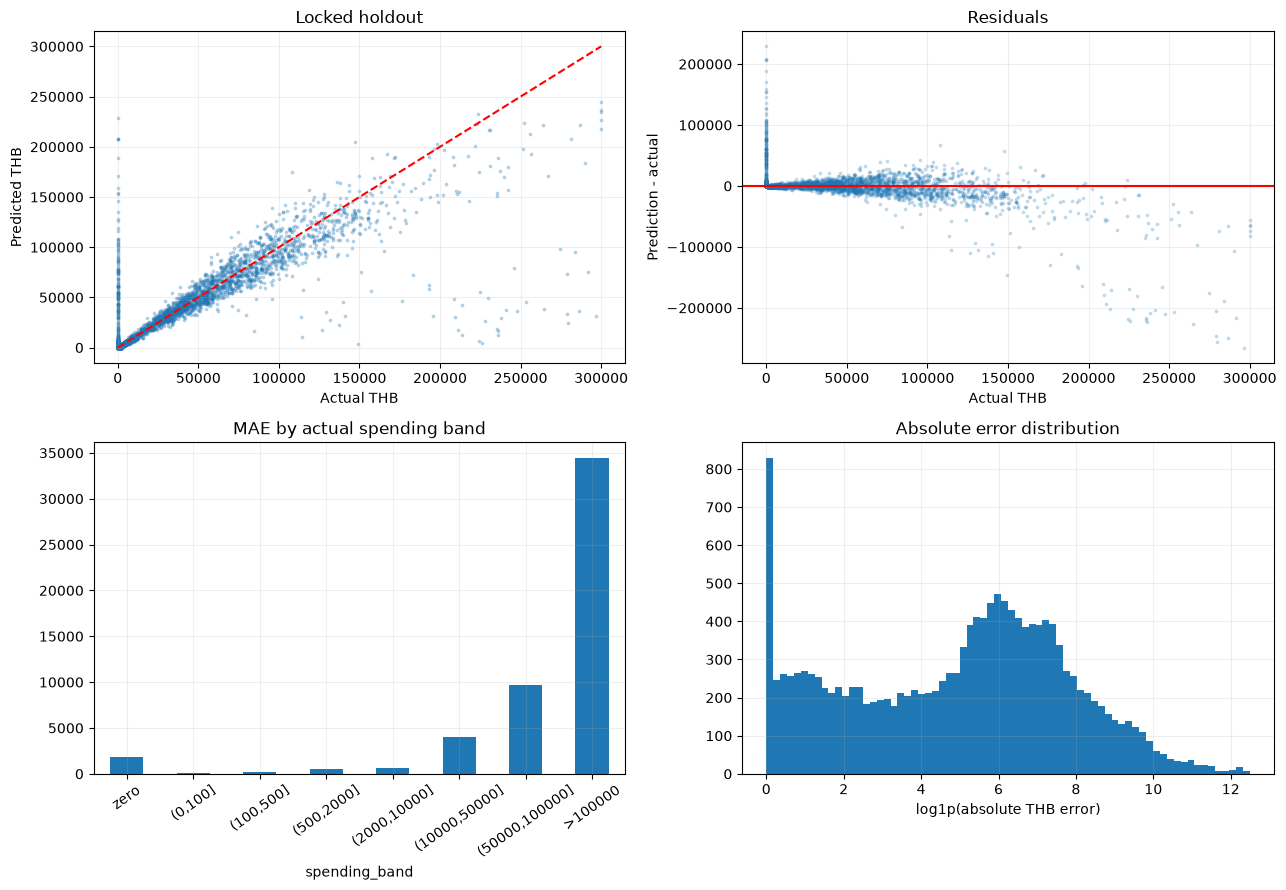

In [28]:
# วาดกราฟ error analysis 4 รูป แล้วบันทึกเป็น holdout_error_analysis.png
fig,ax=plt.subplots(2,2,figsize=(13,9))
# ซ้ายบน: ยอดจริงกับคำทำนาย (เส้นแดง = ทายตรง)
ax[0,0].scatter(yh,hold_pred,s=3,alpha=.25); ax[0,0].plot([0,yh.max()],[0,yh.max()],'r--'); ax[0,0].set(xlabel='Actual THB',ylabel='Predicted THB',title='Locked holdout')
# ขวาบน: residual (คำทำนาย − ยอดจริง)
ax[0,1].scatter(yh,hold_pred-yh,s=3,alpha=.2); ax[0,1].axhline(0,color='r'); ax[0,1].set(xlabel='Actual THB',ylabel='Prediction - actual',title='Residuals')
# ซ้ายล่าง: MAE ตามช่วงยอดเงิน
band.MAE.plot.bar(ax=ax[1,0],title='MAE by actual spending band',rot=35)
# ขวาล่าง: การกระจายของ absolute error บน log scale
ax[1,1].hist(np.log1p(abs_error),bins=70); ax[1,1].set(title='Absolute error distribution',xlabel='log1p(absolute THB error)')
plt.tight_layout(); plt.savefig(FIG/'holdout_error_analysis.png',dpi=140); plt.show()
band.to_csv(OUT/'holdout_error_bands.csv')

**อธิบายกราฟ `holdout_error_analysis.png`:**

- **ซ้ายบน (Actual vs Predicted):** จุดที่อยู่ใกล้เส้นแดงคือทายแม่น ช่วงยอดต่ำถึงกลางจุดเกาะเส้นดี แต่ช่วงยอดสูงจุดส่วนใหญ่อยู่ **ใต้เส้น** โมเดลจึงทายคนจ่ายหนักต่ำกว่าจริง
- **ขวาบน (Residuals):** ด้านขวาของกราฟ residual ลงต่ำกว่า 0 ชัดเจน ยืนยันว่าทายต่ำไปเมื่อยอดจริงสูง และมีแท่งจุดแนวตั้งที่ยอดจริง 0 บาท residual บวกสูงถึงกว่า 200,000 บาท คือผู้เล่นที่โมเดลคิดว่าจะจ่ายหนักแต่จริงไม่จ่ายเลย
- **ซ้ายล่าง (MAE ตามช่วงยอดเงิน):** ตั้งแต่ช่วง 0–100 บาทขึ้นไป แท่งสูงขึ้นตามยอดเงินจริง จนกลุ่มเกิน 100,000 บาทมี MAE ประมาณ 34,400 บาท ส่วนแท่ง `zero` (7,507 แถว) สูงกว่ากลุ่มยอดต่ำ เพราะโมเดลทายเฉลี่ย 1,838 บาทให้คนที่จริงไม่จ่าย
- **ขวาล่าง (การกระจายของ error บน log scale):** แท่งที่ 0 คือแถวที่ทายถูกเป๊ะ (ส่วนใหญ่ทาย 0 กับคนไม่จ่าย) ก้อนใหญ่อยู่ราว log 5–8 หรือ error หลักร้อยถึงสองพันบาท และมีหางยาวไปถึง log 12 (error เกิน 100,000 บาท) จำนวนน้อย

**ตัวเลขสำคัญ:**
- ผู้เล่น top 1% ของ holdout (ยอดจริงเกิน 146,143 บาท) มี MAE ประมาณ 67,880 บาท และสร้าง error ถึง **24.2%** ของ error ทั้งหมด
- กลุ่ม `zero` แม้ MAE ต่อแถวไม่สูง แต่มีจำนวนแถวมาก จึงสร้าง error รวม **31.5%** ส่วนกลุ่มเกิน 100,000 บาทสร้าง **36.5%**
- แถวที่ขาดข้อมูล 4 ช่องขึ้นไปมี MAE **3,880 บาท** สูงกว่าแถวที่ข้อมูลครบ (2,596 บาท)
- error สูงสุดหลายแถวเป็นผู้เล่นที่จ่ายจริงเกือบ 300,000 บาท แต่โมเดลทายเพียง 25,000–40,000 บาท ยอดระดับนี้คาดเดาได้ยากจากข้อมูลย้อนหลัง

**ความหมาย:** error ส่วนใหญ่มาจากสองปลาย คือคนที่ทายว่าจะจ่ายแต่จริงไม่จ่าย กับคนจ่ายหนักที่ทายต่ำไป จุดที่จะพัฒนาต่อได้จึงเป็น classifier "จะจ่ายไหม", กลุ่มคนจ่ายหนัก และแถวที่ขาดข้อมูล ส่วนกลุ่มยอดต่ำถึงกลางทำได้ดีอยู่แล้ว

## 13. Feature importance

ใช้ **permutation importance** กับโมเดลที่มีน้ำหนักมากที่สุดใน ensemble โดยฝึกบน fold แรกของ dev แล้วสุ่มสลับค่าทีละ feature บน 2,500 แถวของ fold ที่วัดผล (ทำซ้ำ 2 รอบ) ถ้า MAE เพิ่มมาก แปลว่าโมเดลพึ่ง feature นั้นมาก

ไม่ได้ใช้ holdout ในขั้นนี้ และไม่ได้ใช้ผลนี้เลือก feature รอบใหม่

In [29]:
# คำนวณ permutation importance บน fold ของ dev
# เลือกโมเดลตัวแทน = โมเดลที่มีน้ำหนักมากที่สุดใน ensemble
if winner=='weighted':representative=shortlist[int(np.argmax(weights))]
elif winner=='single':representative=shortlist[best_single]
else:representative=shortlist[best_single]
spec=specs[representative]; x=X_fe if spec.fe else X_raw
a,b=folds[0]
# ฝึกบน fold แรกของ dev
imp_model=copy.deepcopy(spec).fit(x.iloc[dev_idx[a]],y_all.iloc[dev_idx[a]],rounds=cv_iterations[representative])
rng=np.random.default_rng(SEED)
perm_rows=rng.choice(dev_idx[b],size=min(2500,len(b)),replace=False)
# Candidate is a light wrapper; calculate directly to avoid estimator tag/version assumptions.
xp=x.iloc[perm_rows].copy(); yp=y_all.iloc[perm_rows].to_numpy()
# MAE ก่อนสลับ แล้วสลับทีละ feature เพื่อดูว่า MAE เพิ่มเท่าไร
base_mae=mean_absolute_error(yp,imp_model.predict(xp))
importance_rows=[]
for c in xp.columns:
    increases=[]
    for repeat in range(2):
        shuffled=xp.copy(); shuffled[c]=rng.permutation(shuffled[c].to_numpy())
        increases.append(mean_absolute_error(yp,imp_model.predict(shuffled))-base_mae)
    importance_rows.append({'feature':c,'MAE_increase':np.mean(increases),'std':np.std(increases)})
importance=pd.DataFrame(importance_rows).sort_values('MAE_increase',ascending=False)
display(importance.head(25))

,feature,MAE_increase,std
34,history_with_transaction_fallback,7224.169311,129.647944
47,vip_spending_interaction,1055.956198,73.998045
31,segment,456.341533,3.393599
22,days_since_last_purchase,273.798436,32.307428
46,premium_spending_interaction,261.452898,0.341331
27,seasonal_spending_pattern,219.443074,3.341847
11,historical_spending,150.198838,21.422278
19,games_played,149.362659,27.998274
12,prev_month_spending,110.408435,12.674660
45,event_spending_interaction,65.763210,4.191414


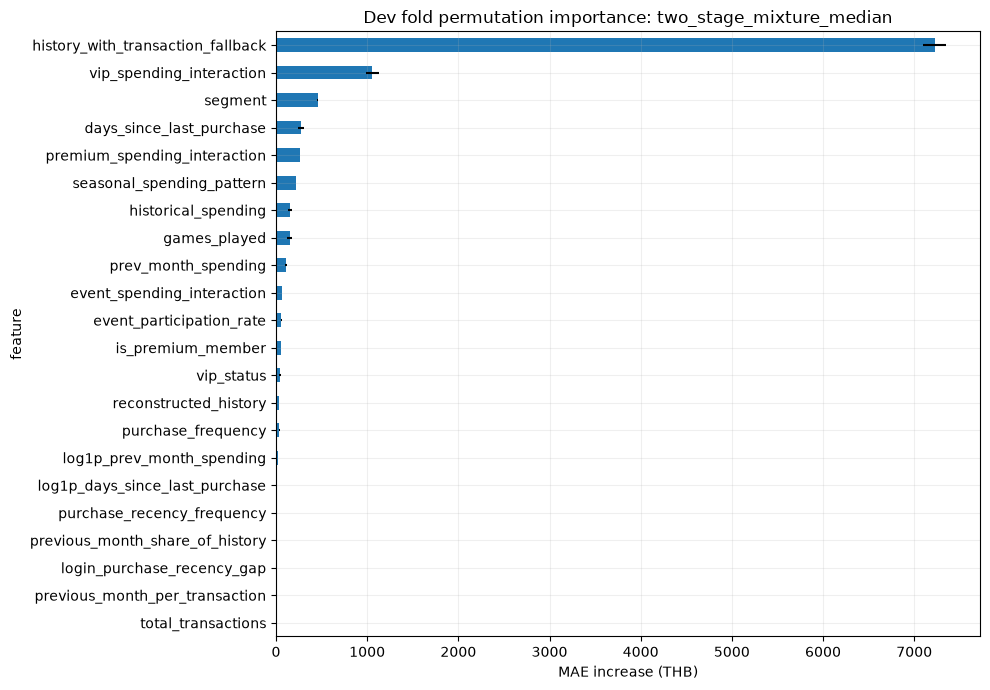

In [30]:
# วาดกราฟ importance 22 อันดับแรก แล้วบันทึกเป็น permutation_importance.png
importance.head(22).sort_values('MAE_increase').plot.barh(x='feature',y='MAE_increase',xerr='std',legend=False,figsize=(10,7),title='Dev fold permutation importance: '+representative)
plt.xlabel('MAE increase (THB)'); plt.tight_layout(); plt.savefig(FIG/'permutation_importance.png',dpi=140); plt.show()
importance.to_csv(OUT/'permutation_importance.csv',index=False)

**อธิบายกราฟ `permutation_importance.png`:** แกนนอนคือ MAE ที่เพิ่มขึ้น (บาท) เมื่อสลับค่า feature นั้น เส้นขีดคือส่วนเบี่ยงเบนของ 2 รอบ โมเดลตัวแทนคือ `two_stage_mixture_median` (น้ำหนัก 0.51)

- `history_with_transaction_fallback` สำคัญที่สุดแบบทิ้งห่าง (MAE เพิ่ม **7,224 บาท**) feature นี้คือยอดซื้อย้อนหลังที่เติมด้วยยอดสร้างใหม่เมื่อข้อมูลหาย ยืนยันว่า feature engineering ในขั้นที่ 6 มีประโยชน์จริง
- ตามด้วย `vip_spending_interaction` (1,056 บาท), `segment` (456 บาท), `days_since_last_purchase` (274 บาท) และ `premium_spending_interaction` (261 บาท)
- `historical_spending` เดิมได้ importance เพียง 150 บาท เพราะสัญญาณส่วนใหญ่ถูกแบ่งไปที่ feature ที่สร้างจากมันแล้ว

**ข้อควรระวัง:** features ที่สัมพันธ์กันสูงจะแบ่ง importance กัน ค่า importance ไม่ได้บอกเหตุและผล และกราฟนี้มาจากโมเดลตัวแทนตัวเดียว ไม่ใช่ทั้ง ensemble

## 14. ฝึกด้วย train ทั้งหมดและสร้างไฟล์ผลทำนาย

### 14.1 Final refit

หลังวัดผล holdout แล้ว นำ train ทั้งหมด 104,000 แถวมาฝึกโมเดลใน ensemble ใหม่ ด้วย specification, จำนวนรอบ และน้ำหนักเดิมที่ตรึงไว้ ไม่ใช้ test ทำ early stopping

คำทำนายถูกจำกัดไม่ให้ต่ำกว่า 0 บาท แต่ไม่ได้ตัดเพดานด้านบนที่ 300,000 บาท

In [31]:
# ฝึกโมเดลใน ensemble ใหม่ด้วย train ทั้งหมด แล้วทำนาย test
test_matrix=np.zeros((len(test),k)); final_models={}
for j in active:
    name=shortlist[j]; spec=specs[name]
    x=X_fe if spec.fe else X_raw
    # สร้าง features ของ test ด้วยฟังก์ชันเดียวกับ train และตรวจลำดับคอลัมน์
    xt=make_features(test,spec.fe)
    assert list(x.columns)==list(xt.columns)
    model=copy.deepcopy(spec).fit(x,y_all,rounds=cv_iterations[name])
    test_matrix[:,j]=model.predict(xt); final_models[name]=model
    print('Final full-train fit complete:',name,flush=True)
# รวมด้วยน้ำหนักเดิมและบังคับไม่ให้ติดลบ
prediction=np.maximum(combine(test_matrix),0)
assert prediction.shape==(25889,) and np.isfinite(prediction).all()

Final full-train fit complete: two_stage_mixture_median


Final full-train fit complete: lightgbm_optuna_l1


Final full-train fit complete: lightgbm_fe_l1


Final full-train fit complete: lightgbm_raw_l1


### 14.2 บันทึกไฟล์รายละเอียดและ run manifest

`submissions/task3_predictions_detail.csv` มีคอลัมน์ `row_index`, `player_id` และ `prediction` เรียงตามลำดับ test เดิมโดยไม่ sort และอ่านไฟล์กลับมาตรวจอีกครั้ง

`models/Task3/run_manifest.json` บันทึก seed, น้ำหนัก ensemble, best params, คะแนน, เวอร์ชันไลบรารี และ hash ของข้อมูล เพื่อให้คนอื่นทำซ้ำได้

In [32]:
# บันทึกไฟล์คำทำนายแบบละเอียดและ run manifest
submission=pd.DataFrame({'row_index':np.arange(len(test),dtype=int),ID:test[ID].to_numpy(),'prediction':prediction})
assert submission.columns.tolist()==['row_index','player_id','prediction']
assert submission[ID].equals(test[ID].reset_index(drop=True))
assert submission.prediction.ge(0).all() and pd.api.types.is_numeric_dtype(submission.prediction)
PRED_PATH=SUB/'task3_predictions_detail.csv'
submission.to_csv(PRED_PATH,index=False,float_format='%.8f')
# อ่านไฟล์กลับมาตรวจขนาด ลำดับ ID และค่าที่ต้องไม่ติดลบ
roundtrip=pd.read_csv(PRED_PATH)
assert roundtrip.shape==(25889,3) and roundtrip[ID].tolist()==test[ID].tolist()
assert roundtrip.row_index.tolist()==list(range(len(test)))
assert np.isfinite(roundtrip.prediction).all() and roundtrip.prediction.ge(0).all()
display(submission.head(10)); display(submission.prediction.describe(percentiles=[.5,.9,.95,.99]))
# บันทึกทุกอย่างที่ต้องใช้ทำซ้ำผลนี้
manifest={'metric':'NMAE = 1 / (1 + sum(abs(y - prediction)) / sum(y)); higher is better',
          'metric_source':'User-provided project slides, pages 19 and 25',
          'selection_objective':'original-scale MAE; equivalent ranking to NMAE on the same rows',
          'seed':SEED,'folds':N_FOLDS,'optuna_trials':N_TRIALS,'threads':THREADS,
          'selected_strategy':winner,'shortlist':shortlist,'active_models':[shortlist[j] for j in active],
          'weights':weights.tolist(),'best_single':shortlist[best_single],
          'rounds':cv_iterations,'optuna_best_params':study.best_params,
          'selected_oof_mae':float(mean_absolute_error(yd,selected_dev_prediction)),
          'selected_oof_nmae':nmae_score(yd,selected_dev_prediction),
          'locked_holdout':{key:float(value) for key,value in hold_metrics.items()},
          'locked_holdout_mae_95pct_ci':ci.tolist(),'versions':versions,'data_sha256':fingerprints,
          'output_rows':len(submission),'row_index_base':0,'prediction_file':PRED_PATH.relative_to(ROOT).as_posix(),
          'target_facts':target_facts,
          'candidate_specs':{n:{'kind':s.kind,'engineered':s.fe,'params':s.params,'transform':s.transform,'upper_clip':s.upper_clip} for n,s in specs.items()}}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Saved and validated:',PRED_PATH.relative_to(ROOT).as_posix())
display(Markdown(f"**ผลรันจริง:** เลือก `{winner}` จาก dev-only OOF, locked holdout MAE = **{hold_metrics['MAE']:,.3f} บาท**, "
                 f"RMSE = **{hold_metrics['RMSE']:,.3f} บาท**, R² = **{hold_metrics['R2']:.4f}**. "
                 f"NMAE ตามสไลด์ = **{hold_metrics['NMAE']:.5f}** บน locked holdout. "
                 f"สร้าง prediction ครบ **{len(submission):,} แถว**. คะแนนนี้ไม่ใช่ leaderboard score."))

,row_index,player_id,prediction
0,0,P030374,10.120755
1,1,P113216,2176.542554
2,2,P015351,1.447287
3,3,P095374,44.555810
4,4,P059369,21.271575
5,5,P038141,15.611468
6,6,P026891,9.159403
7,7,P066584,3339.664396
8,8,P086807,1.068157
9,9,P102109,129.894135


count     25889.000000
mean      10377.338039
std       27319.035475
min           0.000000
50%         139.885329
90%       41799.314436
95%       76293.521898
99%      132183.861971
max      250634.063031
Name: prediction, dtype: float64

Saved and validated: submissions/task3_predictions_detail.csv


**ผลรันจริง:** เลือก `weighted` จาก dev-only OOF, locked holdout MAE = **2,808.123 บาท**, RMSE = **13,297.086 บาท**, R² = **0.8104**. NMAE ตามสไลด์ = **0.78903** บน locked holdout. สร้าง prediction ครบ **25,889 แถว**. คะแนนนี้ไม่ใช่ leaderboard score.

### 14.3 ไฟล์ส่งตามรูปแบบของทีม

สร้าง `submissions/task3.csv` ที่มีคอลัมน์ `id,task3` สำหรับนำไปรวมกับ task อื่น แถวที่ i ของ `test.csv` ตรงกับแถวที่ i ของ `sample_submission.csv` จึงนำ `id` จาก sample มาเรียงคู่กับคำทำนายตามลำดับ

In [33]:
# สร้างไฟล์ submissions/task3.csv ในรูปแบบ id,task3 ตามข้อตกลงของทีม
# จับคู่ id ด้วยลำดับแถว: แถวที่ i ของ test.csv = แถวที่ i ของ sample_submission
sample = pd.read_csv(ROOT / 'data' / 'raw' / 'sample_submission.csv')
assert len(sample) == len(test) == 25889
task3_csv = pd.DataFrame({'id': sample['id'], 'task3': prediction})
assert task3_csv['task3'].ge(0).all() and task3_csv['id'].is_unique
TASK3_PATH = SUB / 'task3.csv'
task3_csv.to_csv(TASK3_PATH, index=False, float_format='%.8f')
check = pd.read_csv(TASK3_PATH)
assert check.shape == (25889, 2) and check.columns.tolist() == ['id', 'task3']
print('Saved team-format file:', TASK3_PATH.relative_to(ROOT).as_posix())
display(task3_csv.head())

Saved team-format file: submissions/task3.csv


,id,task3
0,ANS00001,10.120755
1,ANS00002,2176.542554
2,ANS00003,1.447287
3,ANS00004,44.555810
4,ANS00005,21.271575


**ผลลัพธ์:** ได้คำทำนายครบ 25,889 แถว ไม่มีค่าติดลบ ค่าเฉลี่ยของคำทำนายประมาณ 10,377 บาท ใกล้กับค่าเฉลี่ยของ train (10,497 บาท) ส่วน median ประมาณ 140 บาท และค่าสูงสุดประมาณ 250,634 บาท การกระจายนี้สอดคล้องกับ target ใน train

## 15. สรุปผล

### 15.1 สรุป

- ข้อมูลเป็น zero-inflated (ศูนย์ 48%) และหางขวาหนัก จึงเลือก loss แบบ L1/median และโมเดล two-stage
- โมเดลสุดท้ายคือ **weighted ensemble** ของ two-stage mixture median (0.51), LightGBM ที่จูนด้วย Optuna (0.39) และ LightGBM raw (0.10)
- ผลบน locked holdout: **NMAE 0.78903**, MAE 2,808 บาท และ R² 0.810 ดีกว่า baseline ที่ทาย median ทุกคนมาก (MAE 10,502 บาท)

### 15.2 การใช้คำใบ้อาจารย์ของ Task 3

| คำใบ้ | ทำในขั้น | ผล |
|---|---|---|
| Zero-inflated two-stage (จะจ่ายไหม / จ่ายเท่าไร) | 7, 8 | `two_stage_mixture_median` เป็นโมเดลเดี่ยวที่ดีที่สุด และได้น้ำหนักสูงสุดใน ensemble |
| Feature engineering | 6, 8, 13 | MAE ลดลง 67–283 บาท และ feature ที่สร้างขึ้นสำคัญที่สุดใน permutation importance |
| Log target | 7 | ทดลอง `log1p` ทั้ง L1 และ L2 แล้วแปลงกลับก่อนวัด แต่ MAE แย่กว่า L1 บนบาทจริง จึงไม่ได้เลือก |
| XGBoost / LightGBM / CatBoost regressors | 7, 9 | ทดลองครบทั้งสาม LightGBM ได้ผลดีที่สุดและถูกจูนต่อด้วย Optuna |
| Ensemble / stacking | 10 | weighted ensemble จาก OOF ลด MAE ได้ประมาณ 15 บาทเทียบกับโมเดลเดี่ยวที่ดีที่สุด |

### 15.3 การทดลองเพิ่มเติมนอก notebook

ไฟล์ Task 3 ที่ส่ง Kaggle รอบล่าสุดผสม ensemble ของ notebook นี้ **75%** กับ MLP ที่ฝึกด้วย L1 loss บนหน่วยบาท **25%** ส่วน MLP ฝึกแยกในสคริปต์ จึงไม่อยู่ใน notebook นี้ บน OOF ของ dev ผลผสมนี้ยก NMAE จาก 0.785820 เป็น 0.787064

Kaggle รายงานเป็นคะแนนรวมของ 5 tasks จึงไม่ทราบคะแนน Kaggle ของ Task 3 อย่างเดียว ตัวเลขใน notebook นี้ทั้งหมดเป็น local validation

### 15.4 ข้อจำกัด

- ผู้เล่นยอดสูงสุด 1% สร้าง error ประมาณหนึ่งในสี่ และโมเดลมักทายต่ำกว่าจริงในกลุ่มนี้
- ข้อมูลไม่มี timestamp จึงยืนยันไม่ได้ว่า features ย้อนหลังและ `segment` ถูกสร้างก่อนช่วง 30 วันที่ทำนายทุกแถว
- คะแนน OOF มี optimistic bias เล็กน้อยจากการจูนและการหาน้ำหนักบนข้อมูลชุดเดียวกัน ส่วน locked holdout ไม่ได้ใช้เลือกโมเดล จึงเป็นตัวเลขที่ควรใช้อ้างอิง
- ไม่ได้อ้างว่าพบโมเดลที่ดีที่สุดแล้ว เพราะ search space และจำนวน trials มีจำกัด